Importing and configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

Load dataset

In [3]:
df = pd.read_csv(r"C:\Users\user\Downloads\archive (1)\Unemployment in India.csv")

In [5]:
print("Dimensions :", df.shape)
df.head()

Dimensions : (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [6]:
df.tail()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
767,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Structure and types 

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB


In [8]:
df.dtypes

Region                                          str
 Date                                           str
 Frequency                                      str
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                            str
dtype: object

Descriptive statistics 

In [9]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [10]:
df.describe(include="object")

,Region,Date,Frequency,Area
count,740,740,740,740
unique,28,14,2,2
top,Andhra Pradesh,31-10-2019,Monthly,Urban
freq,28,55,381,381


In [11]:
print("Valeurs manquantes :")
print(df.isnull().sum())

print("\nDoublons :", df.duplicated().sum())

print("\nNoms de colonnes (repérez les espaces cachés) :")
print(df.columns.tolist())

Valeurs manquantes :
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Doublons : 27

Noms de colonnes (repérez les espaces cachés) :
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


Explore categorical values

In [12]:
print("Régions :", df["Region"].nunique())
print(df["Region"].unique())

Régions : 28
<StringArray>
[  'Andhra Pradesh',            'Assam',            'Bihar',
     'Chhattisgarh',            'Delhi',              'Goa',
          'Gujarat',          'Haryana', 'Himachal Pradesh',
  'Jammu & Kashmir',        'Jharkhand',        'Karnataka',
           'Kerala',   'Madhya Pradesh',      'Maharashtra',
        'Meghalaya',           'Odisha',       'Puducherry',
           'Punjab',        'Rajasthan',           'Sikkim',
       'Tamil Nadu',        'Telangana',          'Tripura',
    'Uttar Pradesh',      'Uttarakhand',      'West Bengal',
                nan,       'Chandigarh']
Length: 29, dtype: str


## Step 1: Data Understanding and Inspection

### Data Dictionary

| Column | Description | Observed Data Type | Notes |
|---|---|---|---|
| `Region` | Indian state or territory | Text | 28 regions + 1 `NaN` value |
| `Date` | Date of the measurement | Text (`object`) | Needs to be converted to `datetime` |
| `Frequency` | Measurement frequency (monthly) | Text | |
| `Estimated Unemployment Rate (%)` | Percentage of unemployed people in the labour force | Numeric | Min: 0%, Max: 76.74% |
| `Estimated Employed` | Estimated number of employed people | Numeric | Average ≈ 7.2 million |
| `Estimated Labour Participation Rate (%)` | Percentage of the working-age population that is economically active | Numeric | Average ≈ 42.6% |
| `Area` | Geographical area (Urban or Rural) | Text | |

### Key Observations

**Dataset Size**
- 7 columns.
- 740 populated rows, plus 28 empty rows, resulting in a total of 768 rows.

**Data Quality**
- **Missing Values**: 28 in each of the 7 columns. Having the same number of missing values across all columns indicates that these are **completely empty rows**, rather than isolated missing values.
- **Duplicates**: 27 duplicated rows. These are most likely the empty rows (28 empty rows = 1 original + 27 duplicates).
- **Column Names**: Several column names contain **leading spaces** (` Date`, ` Frequency`, ` Estimated Employed`, etc.). These need to be corrected to avoid `KeyError` issues.
- **`Date` Data Type**: Currently stored as text and needs to be converted into a datetime format.

**Descriptive Statistics (Based on the 740 Valid Rows)**

- **Unemployment Rate**: Mean ≈ 11.79%, median = 8.35%, standard deviation ≈ 10.72. The mean is higher than the median, indicating a **right-skewed distribution**, driven by a few extremely high values.
- **Extreme Values**: Minimum = 0% and maximum = 76.74%. The maximum is exceptionally high and is likely related to the COVID-19 lockdown peak (to be verified in Step 5).
- **Estimated Employment**: Very high variability, ranging from 49,420 to 45.8 million people, because regions have significantly different population sizes.
- **Labour Participation Rate**: Ranges from 13.33% to 72.57%, with an average of approximately 42.63%.

### Planned Actions for Step 2 (Data Cleaning)

1. Remove completely empty rows, followed by any remaining duplicate rows.
2. Remove leading and trailing spaces from column names and rename them where necessary.
3. Convert `Date` into the `datetime` data type.
4. Investigate zero values and extreme values (outliers).
5. Create the `year`, `month`, and `period` columns (Pre-COVID / COVID / Post-COVID).

## Step 2: Data Cleaning

Backup copy and removal of empty rows.

In [13]:
df_clean = df.copy()
print("Avant :", df_clean.shape)

# 28 lignes entièrement vides (et leurs doublons)
df_clean = df_clean.dropna(how="all")

print("Après :", df_clean.shape)

Avant : (768, 7)
Après : (740, 7)


Clean column names 

In [14]:
df_clean.columns = df_clean.columns.str.strip()

df_clean = df_clean.rename(columns={
    "Region": "region",
    "Date": "date",
    "Frequency": "frequency",
    "Estimated Unemployment Rate (%)": "unemployment_rate",
    "Estimated Employed": "employed",
    "Estimated Labour Participation Rate (%)": "labour_participation_rate",
    "Area": "area",
})

print(df_clean.columns.tolist())

['region', 'date', 'frequency', 'unemployment_rate', 'employed', 'labour_participation_rate', 'area']


Clean text columns.

In [15]:
for col in ["region", "frequency", "area"]:
    df_clean[col] = df_clean[col].str.strip()

print(df_clean["frequency"].unique())
print(df_clean["area"].unique())

<StringArray>
['Monthly']
Length: 1, dtype: str
<StringArray>
['Rural', 'Urban']
Length: 2, dtype: str


Convert the date.

In [16]:
df_clean["date"] = pd.to_datetime(
    df_clean["date"].str.strip(),
    dayfirst=True,
    errors="coerce"
)

print("Dates non converties :", df_clean["date"].isnull().sum())
print("Période couverte :", df_clean["date"].min(), "→", df_clean["date"].max())
df_clean["date"].dt.to_period("M").value_counts().sort_index()

Dates non converties : 0
Période couverte : 2019-05-31 00:00:00 → 2020-06-30 00:00:00


date
2019-05    54
2019-06    54
2019-07    54
2019-08    53
2019-09    52
2019-10    55
2019-11    55
2019-12    53
2020-01    53
2020-02    53
2020-03    52
2020-04    51
2020-05    51
2020-06    50
Freq: M, Name: count, dtype: int64

Check for missing values and remaining duplicates.

In [17]:
print("Valeurs manquantes :")
print(df_clean.isnull().sum())

print("\nDoublons :", df_clean.duplicated().sum())

Valeurs manquantes :
region                       0
date                         0
frequency                    0
unemployment_rate            0
employed                     0
labour_participation_rate    0
area                         0
dtype: int64

Doublons : 0


Check data consistency.

In [18]:
# Taux hors plage logique (0 à 100)
print("Taux de chômage < 0 :", (df_clean["unemployment_rate"] < 0).sum())
print("Taux de chômage > 100 :", (df_clean["unemployment_rate"] > 100).sum())

# Taux de participation hors plage
print("Participation > 100 :", (df_clean["labour_participation_rate"] > 100).sum())

# Emploi négatif ou nul
print("Emploi <= 0 :", (df_clean["employed"] <= 0).sum())

# Taux à exactement 0 %
print("Taux de chômage = 0 :", (df_clean["unemployment_rate"] == 0).sum())
df_clean[df_clean["unemployment_rate"] == 0]

Taux de chômage < 0 : 0
Taux de chômage > 100 : 0
Participation > 100 : 0
Emploi <= 0 : 0
Taux de chômage = 0 : 11


,region,date,frequency,unemployment_rate,employed,labour_participation_rate,area
25,Assam,2020-06-30,Monthly,0.0,7544937.0,34.38,Rural
51,Chhattisgarh,2020-04-30,Monthly,0.0,6534321.0,39.43,Rural
77,Goa,2020-02-29,Monthly,0.0,171672.0,36.11,Rural
231,Puducherry,2019-05-31,Monthly,0.0,172474.0,43.08,Rural
232,Puducherry,2019-06-30,Monthly,0.0,184527.0,45.95,Rural
233,Puducherry,2019-07-31,Monthly,0.0,139227.0,34.56,Rural
235,Puducherry,2019-09-30,Monthly,0.0,175718.0,43.34,Rural
237,Puducherry,2019-11-30,Monthly,0.0,142787.0,35.00,Rural
274,Sikkim,2020-04-30,Monthly,0.0,133399.0,37.72,Rural
617,Puducherry,2019-06-30,Monthly,0.0,304369.0,37.73,Urban


Detect outliers (IQR method).

In [19]:
Q1 = df_clean["unemployment_rate"].quantile(0.25)
Q3 = df_clean["unemployment_rate"].quantile(0.75)
IQR = Q3 - Q1
borne_basse = Q1 - 1.5 * IQR
borne_haute = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["unemployment_rate"] < borne_basse) |
    (df_clean["unemployment_rate"] > borne_haute)
]

print(f"Bornes : [{borne_basse:.2f} ; {borne_haute:.2f}]")
print("Nombre de valeurs aberrantes :", len(outliers))
outliers.sort_values("unemployment_rate", ascending=False).head(10)

Bornes : [-12.19 ; 32.73]
Nombre de valeurs aberrantes : 35


,region,date,frequency,unemployment_rate,employed,labour_participation_rate,area
627,Puducherry,2020-04-30,Monthly,76.74,68122.0,35.54,Urban
628,Puducherry,2020-05-31,Monthly,75.00,64538.0,31.25,Urban
242,Puducherry,2020-04-30,Monthly,74.51,49420.0,46.79,Rural
531,Jharkhand,2020-05-31,Monthly,70.17,830347.0,40.49,Urban
530,Jharkhand,2020-04-30,Monthly,61.48,1054829.0,39.92,Urban
412,Bihar,2020-04-30,Monthly,58.77,1400962.0,34.94,Urban
145,Jharkhand,2020-05-31,Monthly,55.10,3315038.0,37.03,Rural
287,Tamil Nadu,2020-04-30,Monthly,53.19,5086200.0,33.05,Rural
507,Himachal Pradesh,2020-05-31,Monthly,50.00,134868.0,43.55,Urban
38,Bihar,2020-05-31,Monthly,47.26,14050319.0,38.50,Rural


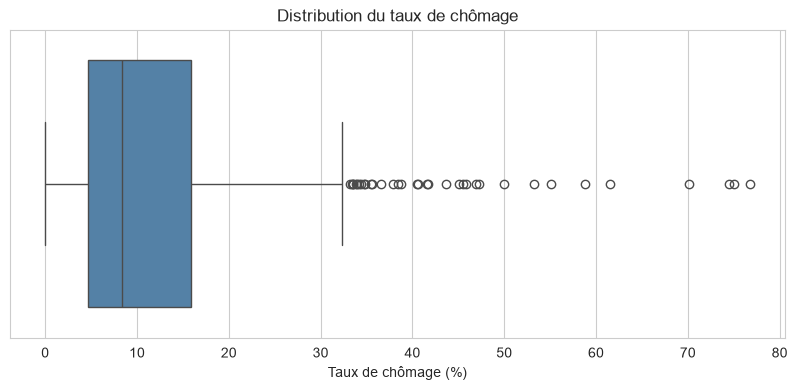

In [20]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_clean["unemployment_rate"], color="steelblue")
plt.title("Distribution du taux de chômage")
plt.xlabel("Taux de chômage (%)")
plt.show()

Create derived columns.

In [21]:
df_clean["year"] = df_clean["date"].dt.year
df_clean["month"] = df_clean["date"].dt.month
df_clean["month_name"] = df_clean["date"].dt.month_name()

# Période : avant / pendant le Covid-19 (confinement national en Inde : 25 mars 2020)
df_clean["period"] = np.where(
    df_clean["date"] < "2020-03-01", "Pré-Covid", "Covid"
)

df_clean["period"].value_counts()

period
Pré-Covid    536
Covid        204
Name: count, dtype: int64

Final validation and saving.

In [22]:
df_clean = df_clean.reset_index(drop=True)

df_clean.info()
df_clean.head()

<class 'pandas.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   region                     740 non-null    str           
 1   date                       740 non-null    datetime64[us]
 2   frequency                  740 non-null    str           
 3   unemployment_rate          740 non-null    float64       
 4   employed                   740 non-null    float64       
 5   labour_participation_rate  740 non-null    float64       
 6   area                       740 non-null    str           
 7   year                       740 non-null    int32         
 8   month                      740 non-null    int32         
 9   month_name                 740 non-null    str           
 10  period                     740 non-null    str           
dtypes: datetime64[us](1), float64(3), int32(2), str(5)
memory usage: 57.9 KB


,region,date,frequency,unemployment_rate,employed,labour_participation_rate,area,year,month,month_name,period
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019,5,May,Pré-Covid
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,2019,6,June,Pré-Covid
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,2019,7,July,Pré-Covid
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,2019,8,August,Pré-Covid
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,2019,9,September,Pré-Covid


In [26]:
df_clean.to_csv("data/cleaned_data.csv", index=False)
print("Fichier sauvegardé :", df_clean.shape)

Fichier sauvegardé : (740, 11)


## Step 2: Data Cleaning

### Operations Performed
1. Removed the 28 completely empty rows (and the 27 associated duplicate rows).
2. Cleaned and renamed the columns (removed extra spaces and converted column names to lowercase).
3. Removed extra spaces from text columns.
4. Converted `date` to `datetime` format (day-month-year).
5. Checked data consistency (unemployment rates between 0 and 100, and employment values greater than zero).
6. Detected outliers using the IQR method: **retained**, as they represent real-world shocks (COVID-19 lockdown) rather than data errors.
7. Created the `year`, `month`, `month_name`, and `period` columns.

### Results
- Final dataset: **740 rows**, with no missing values and no duplicate rows.
- File saved as: `data/cleaned_data.csv`.

## Étape 3 : Analyse exploratoire

Descriptive Statistics.

In [27]:
stats = df_clean["unemployment_rate"].describe()
print(stats)

print("\nMédiane :", df_clean["unemployment_rate"].median())
print("Asymétrie (skewness) :", round(df_clean["unemployment_rate"].skew(), 2))
print("Aplatissement (kurtosis) :", round(df_clean["unemployment_rate"].kurt(), 2))

count    740.000000
mean      11.787946
std       10.721298
min        0.000000
25%        4.657500
50%        8.350000
75%       15.887500
max       76.740000
Name: unemployment_rate, dtype: float64

Médiane : 8.35
Asymétrie (skewness) : 2.22
Aplatissement (kurtosis) : 7.47


Unemployment Rate Distribution.

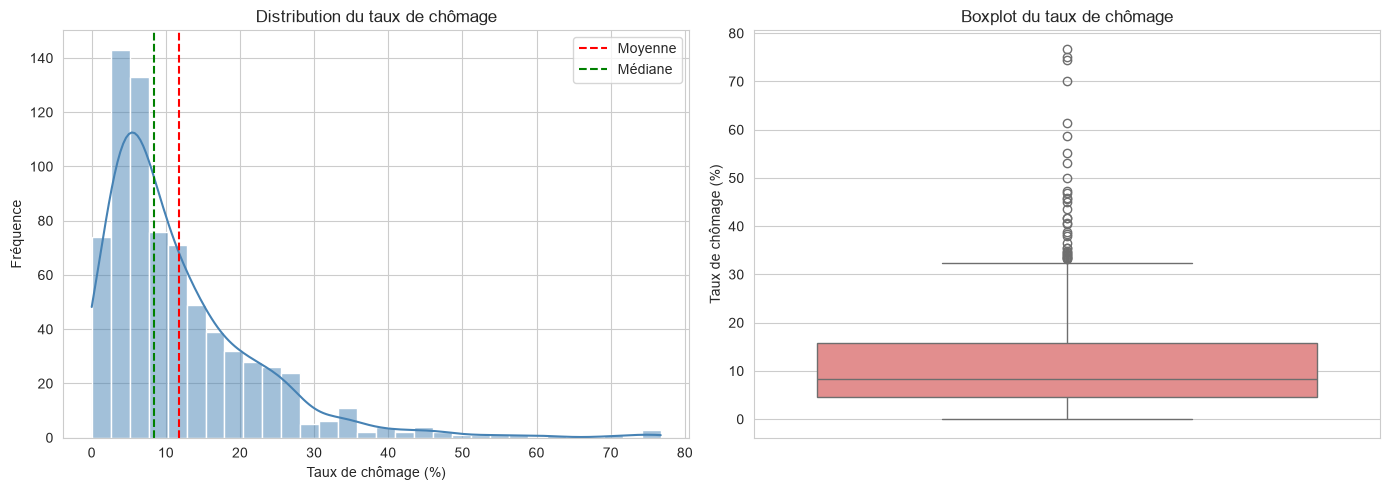

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean["unemployment_rate"], bins=30, kde=True,
             color="steelblue", ax=axes[0])
axes[0].axvline(df_clean["unemployment_rate"].mean(), color="red",
                linestyle="--", label="Moyenne")
axes[0].axvline(df_clean["unemployment_rate"].median(), color="green",
                linestyle="--", label="Médiane")
axes[0].set_title("Distribution du taux de chômage")
axes[0].set_xlabel("Taux de chômage (%)")
axes[0].set_ylabel("Fréquence")
axes[0].legend()

sns.boxplot(y=df_clean["unemployment_rate"], color="lightcoral", ax=axes[1])
axes[1].set_title("Boxplot du taux de chômage")
axes[1].set_ylabel("Taux de chômage (%)")

plt.tight_layout()
plt.savefig("figures/01_distribution_chomage.png", dpi=300, bbox_inches="tight")
plt.show()

Regional Analysis.

In [30]:
region_stats = (
    df_clean.groupby("region")["unemployment_rate"]
    .agg(["mean", "median", "min", "max", "std"])
    .round(2)
    .sort_values("mean", ascending=False)
)
region_stats

,mean,median,min,max,std
region,,,,,
Tripura,28.35,27.31,14.71,43.64,6.06
Haryana,26.28,25.06,14.54,46.89,7.80
Jharkhand,20.58,17.28,5.01,70.17,16.67
Bihar,18.92,15.01,8.87,58.77,12.63
Himachal Pradesh,18.54,18.35,1.12,50.00,9.61
Delhi,16.50,15.02,9.33,45.78,6.79
Jammu & Kashmir,16.19,16.00,2.22,24.06,5.51
Chandigarh,15.99,17.51,7.22,22.05,5.51
Rajasthan,14.06,13.66,4.03,35.53,5.93


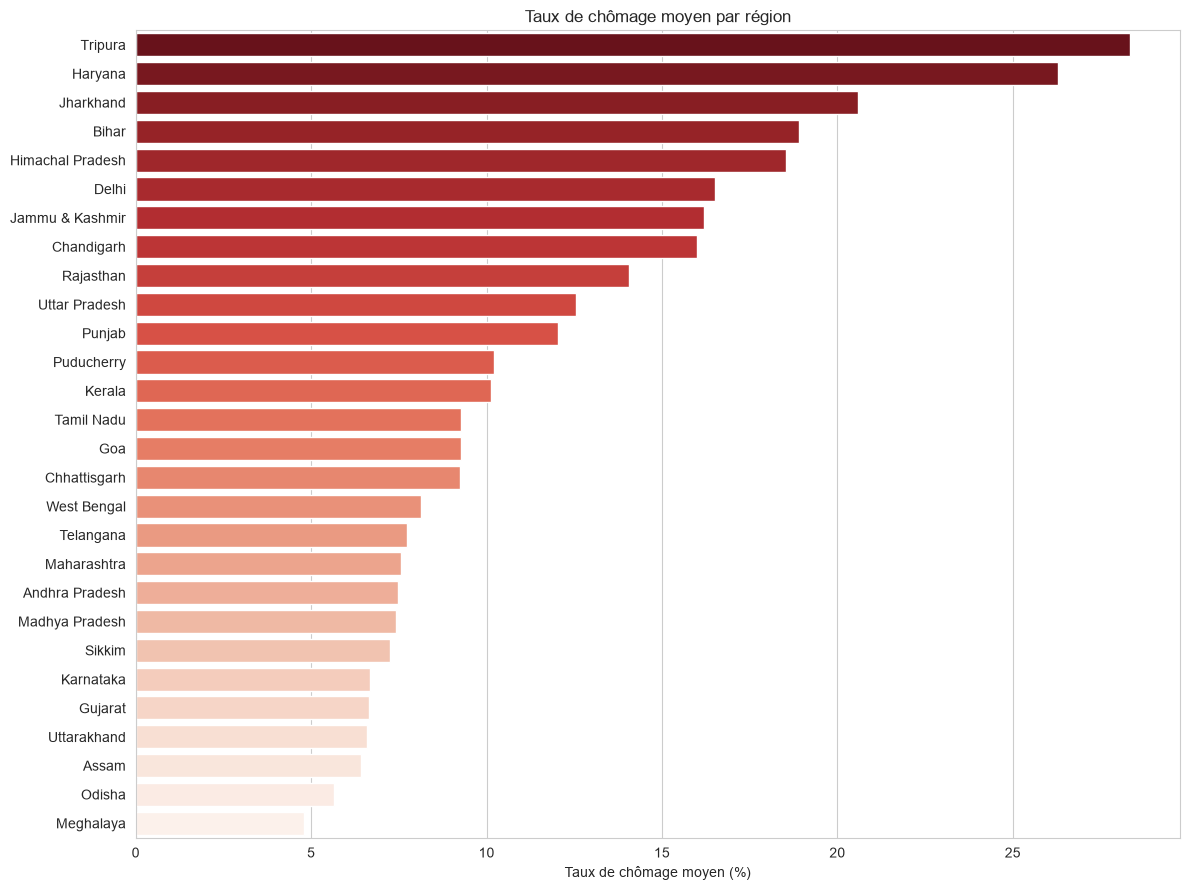

In [32]:
plt.figure(figsize=(12, 9))
ordre = region_stats.index
sns.barplot(
    x=region_stats["mean"], y=ordre,
    order=ordre, palette="Reds_r"
)
plt.title("Taux de chômage moyen par région")
plt.xlabel("Taux de chômage moyen (%)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("figures/02_chomage_par_region.png", dpi=300, bbox_inches="tight")
plt.show()

In [33]:
print("5 régions les plus touchées :")
print(region_stats["mean"].head(5))
print("\n5 régions les moins touchées :")
print(region_stats["mean"].tail(5))

5 régions les plus touchées :
region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Name: mean, dtype: float64

5 régions les moins touchées :
region
Gujarat        6.66
Uttarakhand    6.58
Assam          6.43
Odisha         5.66
Meghalaya      4.80
Name: mean, dtype: float64


Regional Dispersion (Boxplot).

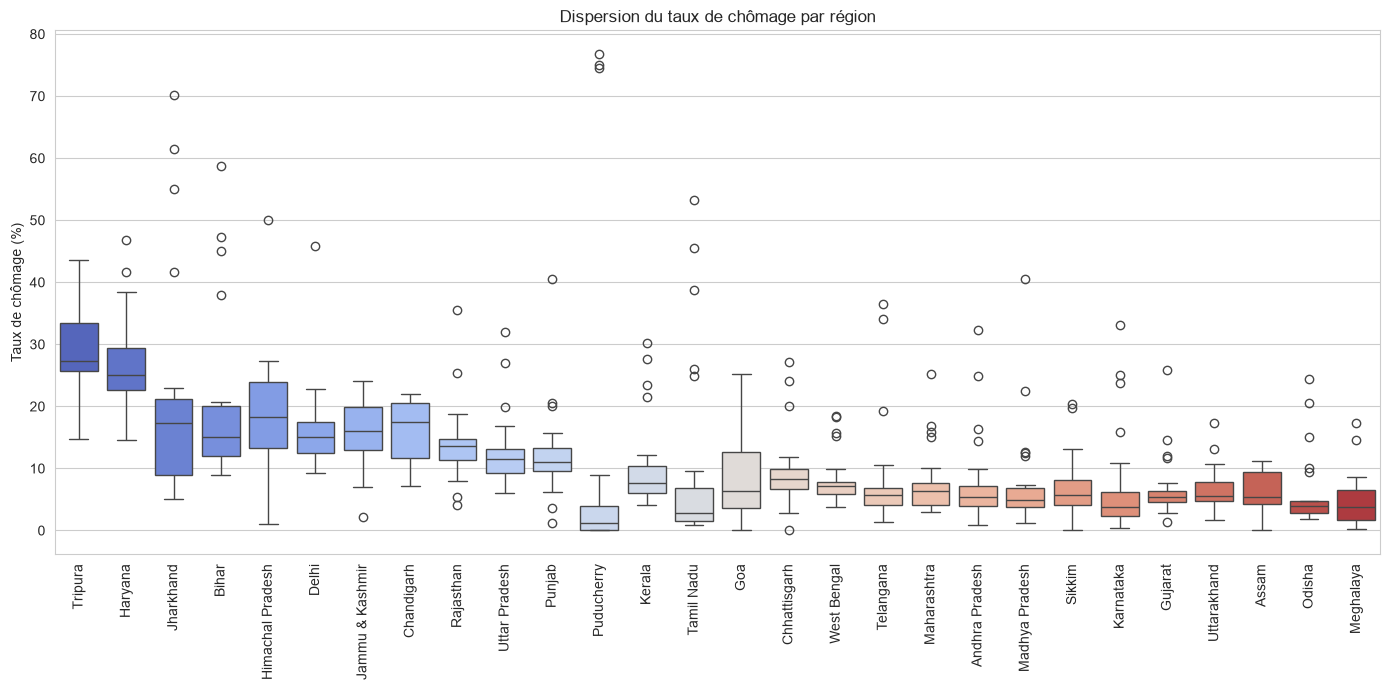

In [35]:
plt.figure(figsize=(14, 7))
sns.boxplot(
    data=df_clean, x="region", y="unemployment_rate",
    order=ordre, palette="coolwarm"
)
plt.xticks(rotation=90)
plt.title("Dispersion du taux de chômage par région")
plt.xlabel("")
plt.ylabel("Taux de chômage (%)")
plt.tight_layout()
plt.savefig("figures/03_boxplot_regions.png", dpi=300, bbox_inches="tight")
plt.show()

Analysis by Area (Urban / Rural).

In [36]:
print(df_clean["area"].value_counts())

area_stats = (
    df_clean.groupby("area")[["unemployment_rate", "employed",
                              "labour_participation_rate"]]
    .mean()
    .round(2)
)
area_stats

area
Urban    381
Rural    359
Name: count, dtype: int64


,unemployment_rate,employed,labour_participation_rate
area,,,
Rural,10.32,10192852.57,44.46
Urban,13.17,4388625.58,40.90


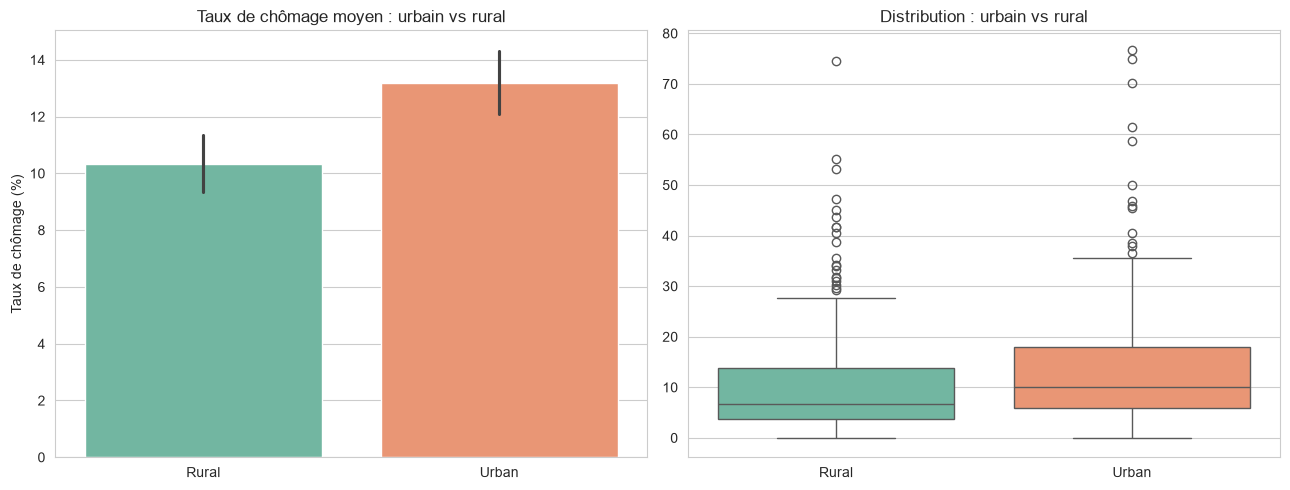

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=df_clean, x="area", y="unemployment_rate",
            palette="Set2", ax=axes[0])
axes[0].set_title("Taux de chômage moyen : urbain vs rural")
axes[0].set_xlabel("")
axes[0].set_ylabel("Taux de chômage (%)")

sns.boxplot(data=df_clean, x="area", y="unemployment_rate",
            palette="Set2", ax=axes[1])
axes[1].set_title("Distribution : urbain vs rural")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("figures/04_urbain_vs_rural.png", dpi=300, bbox_inches="tight")
plt.show()

Overall Pre-COVID vs. COVID Comparison.

In [38]:
period_stats = (
    df_clean.groupby("period")[["unemployment_rate", "labour_participation_rate"]]
    .agg(["mean", "median", "max"])
    .round(2)
)
period_stats

unemployment_rate               labour_participation_rate         \
                       mean median    max                      mean median   
period                                                                       
Covid                 17.77  14.52  76.74                     39.33  38.48   
Pré-Covid              9.51   7.12  34.69                     43.89  42.46   

                  
             max  
period            
Covid      68.53  
Pré-Covid  72.57

Correlation Analysis.

In [39]:
cols_num = ["unemployment_rate", "employed", "labour_participation_rate"]
corr = df_clean[cols_num].corr().round(2)
corr

,unemployment_rate,employed,labour_participation_rate
unemployment_rate,1.00,-0.22,0.00
employed,-0.22,1.00,0.01
labour_participation_rate,0.00,0.01,1.00


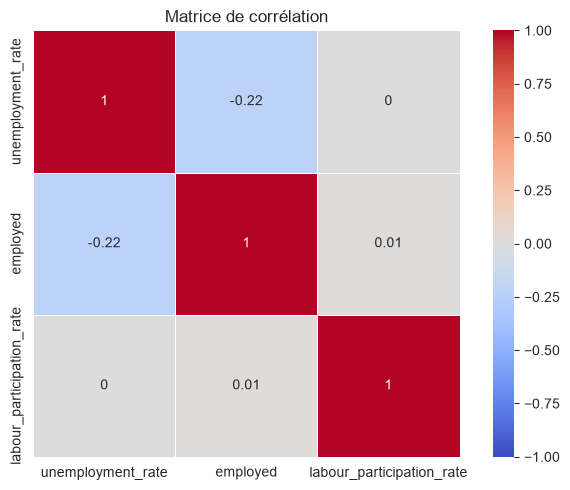

In [40]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.savefig("figures/05_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

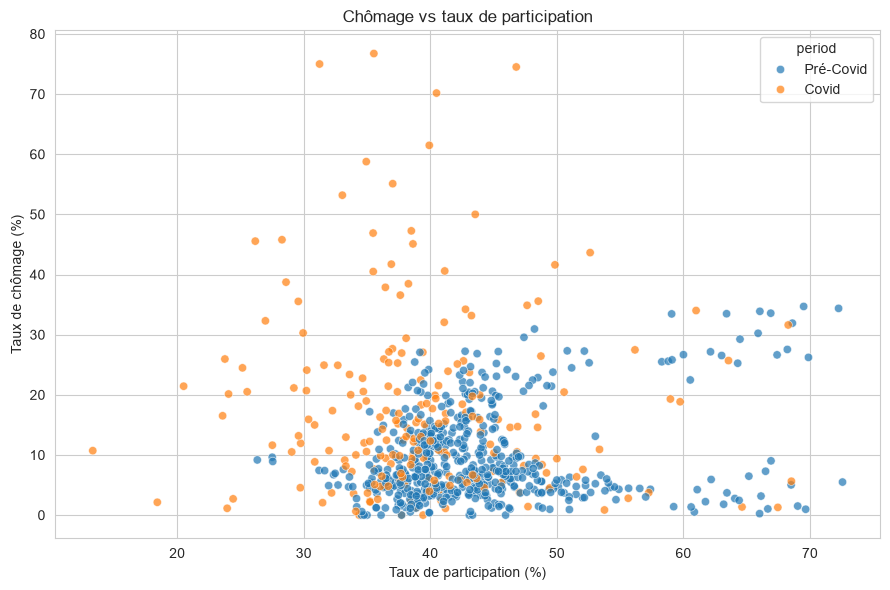

In [41]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_clean, x="labour_participation_rate", y="unemployment_rate",
    hue="period", alpha=0.7
)
plt.title("Chômage vs taux de participation")
plt.xlabel("Taux de participation (%)")
plt.ylabel("Taux de chômage (%)")
plt.tight_layout()
plt.savefig("figures/06_chomage_vs_participation.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 3: Exploratory Data Analysis (EDA)

### Unemployment Rate Distribution
- Mean: [...]%, median: [...]%, standard deviation: [...].
- **Right-skewed distribution** (skewness = [...]), indicating the presence of a few extremely high values.

### Regional Analysis
- Most affected regions: [...], [...], [...] (average unemployment rate ranging from [...]% to [...]%).
- Least affected regions: [...], [...], [...].
- Regions with the highest dispersion (boxplot): [...], suggesting the presence of significant short-term shocks.

### Urban vs. Rural Analysis
- Average urban unemployment rate: [...]%, rural unemployment rate: [...]%.
- [The ... area is more affected.]

### Correlation Analysis
- Unemployment vs. labour participation rate: r = [...].
- Unemployment vs. estimated employment: r = [...] ([weak / strong]).
- Interpretation: [...]

### Initial Overview of COVID-19 Impact
- Average pre-COVID unemployment rate: [...]%, during COVID-19: [...]%.
- To be analyzed in greater detail in Step 5.

## Étape 4 : Analyse des tendances temporelles

Prepare the Monthly Time Series.

In [42]:
df_clean = df_clean.sort_values("date").reset_index(drop=True)

monthly = (
    df_clean.groupby("date")
    .agg(
        unemployment_rate=("unemployment_rate", "mean"),
        participation=("labour_participation_rate", "mean"),
        employed_total=("employed", "sum"),
        n_obs=("region", "count"),
    )
    .round(2)
)
monthly

,unemployment_rate,participation,employed_total,n_obs
date,,,,
2019-05-31,8.87,43.90,400148016.0,54
2019-06-30,9.30,43.75,397366645.0,54
2019-07-31,9.03,43.71,399838967.0,54
2019-08-31,9.64,43.65,399610205.0,53
2019-09-30,9.05,44.30,402452126.0,52
2019-10-31,9.90,44.00,401411032.0,55
2019-11-30,9.87,44.11,400051335.0,55
2019-12-31,9.50,43.67,391001555.0,53
2020-01-31,9.95,44.05,406899254.0,53


Overall Unemployment Rate Trend.

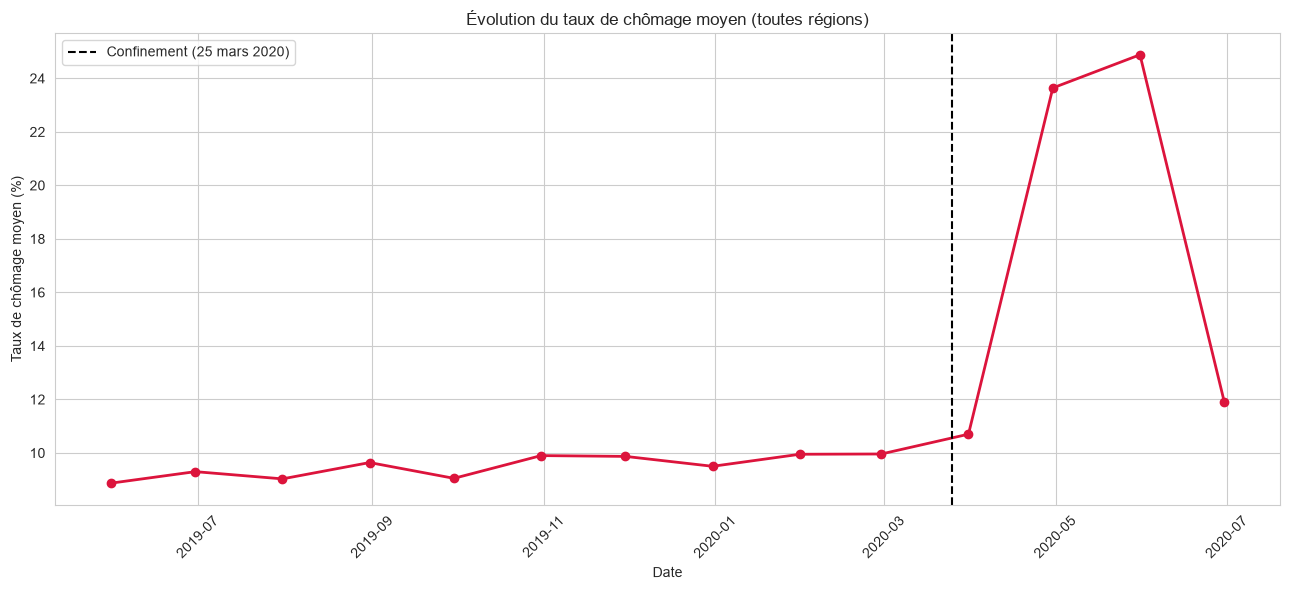

In [44]:
LOCKDOWN = pd.Timestamp("2020-03-25")  # début du confinement national en Inde

plt.figure(figsize=(13, 6))
plt.plot(monthly.index, monthly["unemployment_rate"],
         marker="o", linewidth=2, color="crimson")
plt.axvline(LOCKDOWN, color="black", linestyle="--", label="Confinement (25 mars 2020)")
plt.title("Évolution du taux de chômage moyen (toutes régions)")
plt.xlabel("Date")
plt.ylabel("Taux de chômage moyen (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("figures/07_tendance_globale.png", dpi=300, bbox_inches="tight")
plt.show()

Moving Average (Smoothing).

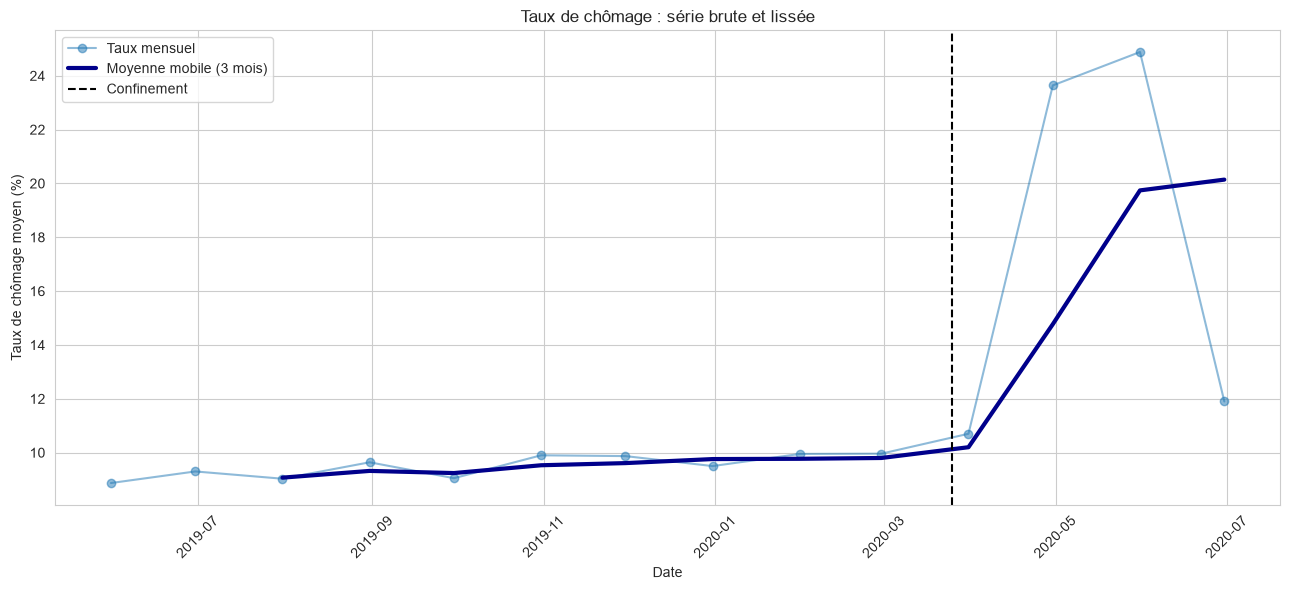

In [46]:
monthly["moyenne_mobile_3m"] = monthly["unemployment_rate"].rolling(window=3).mean().round(2)

plt.figure(figsize=(13, 6))
plt.plot(monthly.index, monthly["unemployment_rate"],
         marker="o", alpha=0.5, label="Taux mensuel")
plt.plot(monthly.index, monthly["moyenne_mobile_3m"],
         linewidth=3, color="darkblue", label="Moyenne mobile (3 mois)")
plt.axvline(LOCKDOWN, color="black", linestyle="--", label="Confinement")
plt.title("Taux de chômage : série brute et lissée")
plt.xlabel("Date")
plt.ylabel("Taux de chômage moyen (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("figures/08_moyenne_mobile.png", dpi=300, bbox_inches="tight")
plt.show()

Monthly and Yearly Aggregation.

In [47]:
par_mois = (
    df_clean.groupby(["year", "month"])["unemployment_rate"]
    .mean().round(2).reset_index()
)
par_mois.pivot(index="month", columns="year", values="unemployment_rate")

year,2019,2020
month,,
1,NaN,9.95
2,NaN,9.96
3,NaN,10.70
4,NaN,23.64
5,8.87,24.88
6,9.30,11.90
7,9.03,NaN
8,9.64,NaN
9,9.05,NaN


In [48]:
par_annee = df_clean.groupby("year")["unemployment_rate"].agg(["mean", "count"]).round(2)
par_annee

,mean,count
year,,
2019,9.4,430
2020,15.1,310


Trends in Total Employment and Labour Force Participation.

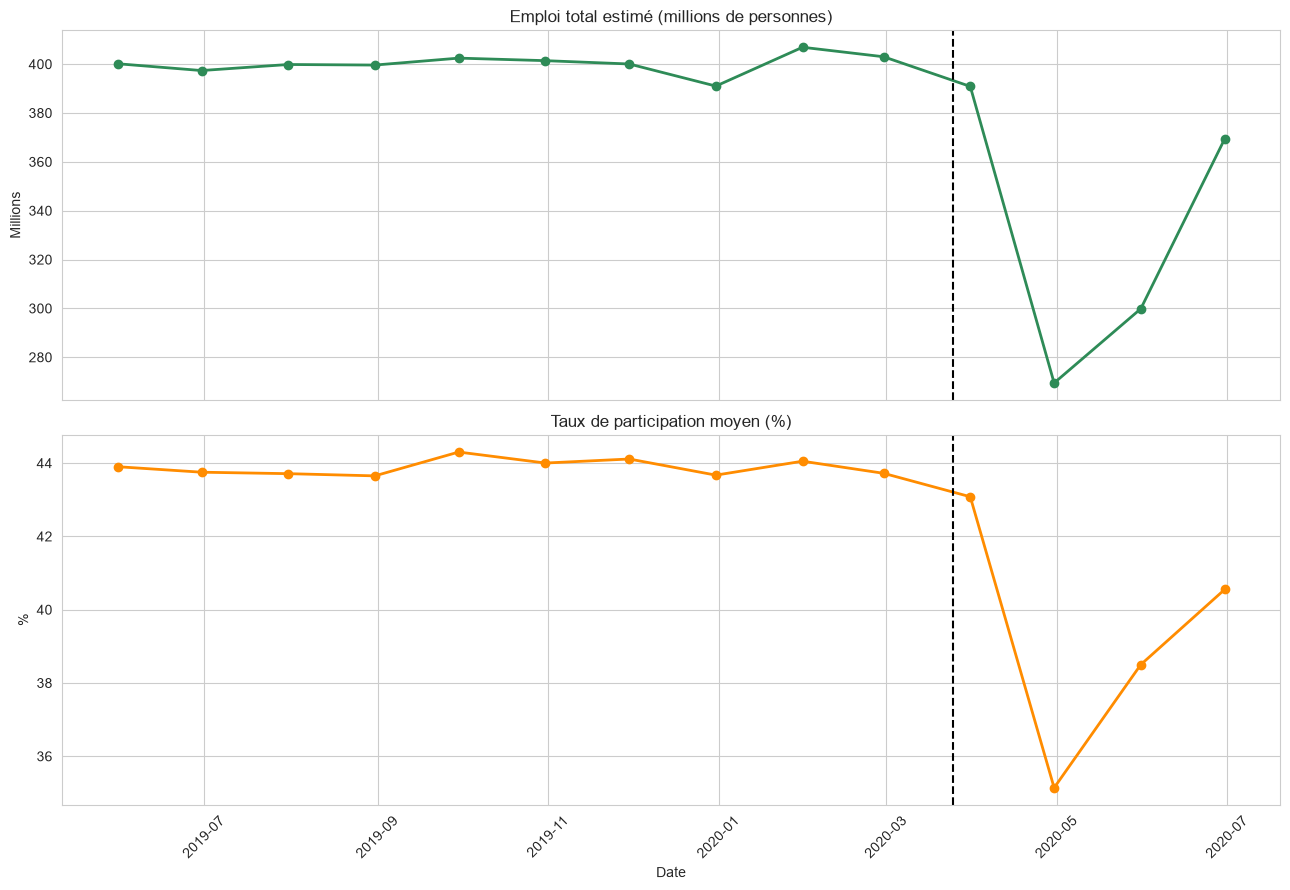

In [50]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

axes[0].plot(monthly.index, monthly["employed_total"] / 1e6,
             marker="o", color="seagreen", linewidth=2)
axes[0].axvline(LOCKDOWN, color="black", linestyle="--")
axes[0].set_title("Emploi total estimé (millions de personnes)")
axes[0].set_ylabel("Millions")

axes[1].plot(monthly.index, monthly["participation"],
             marker="o", color="darkorange", linewidth=2)
axes[1].axvline(LOCKDOWN, color="black", linestyle="--")
axes[1].set_title("Taux de participation moyen (%)")
axes[1].set_ylabel("%")
axes[1].set_xlabel("Date")

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/09_emploi_participation.png", dpi=300, bbox_inches="tight")
plt.show()

Urban vs. Rural Trends Over Time.

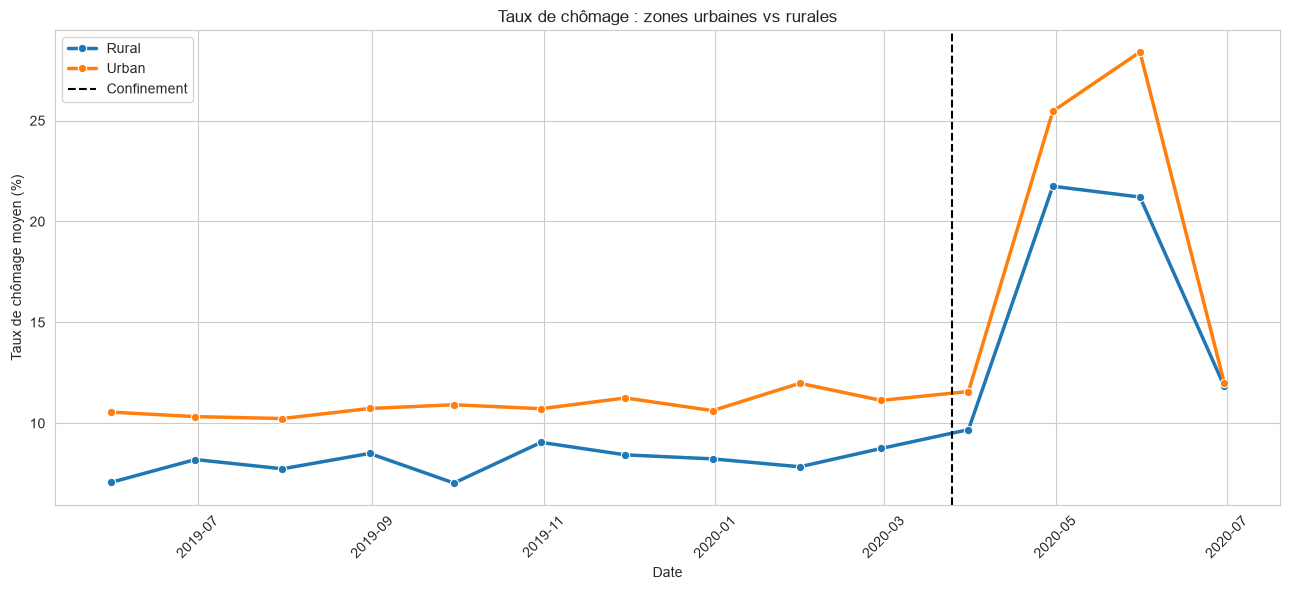

In [52]:
area_time = (
    df_clean.groupby(["date", "area"])["unemployment_rate"]
    .mean().reset_index()
)

plt.figure(figsize=(13, 6))
sns.lineplot(data=area_time, x="date", y="unemployment_rate",
             hue="area", marker="o", linewidth=2.5)
plt.axvline(LOCKDOWN, color="black", linestyle="--", label="Confinement")
plt.title("Taux de chômage : zones urbaines vs rurales")
plt.xlabel("Date")
plt.ylabel("Taux de chômage moyen (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("figures/10_urbain_rural_temps.png", dpi=300, bbox_inches="tight")
plt.show()

Comparison Across Key Regions.

Régions au pic le plus élevé : ['Puducherry', 'Jharkhand', 'Bihar', 'Tamil Nadu', 'Himachal Pradesh']


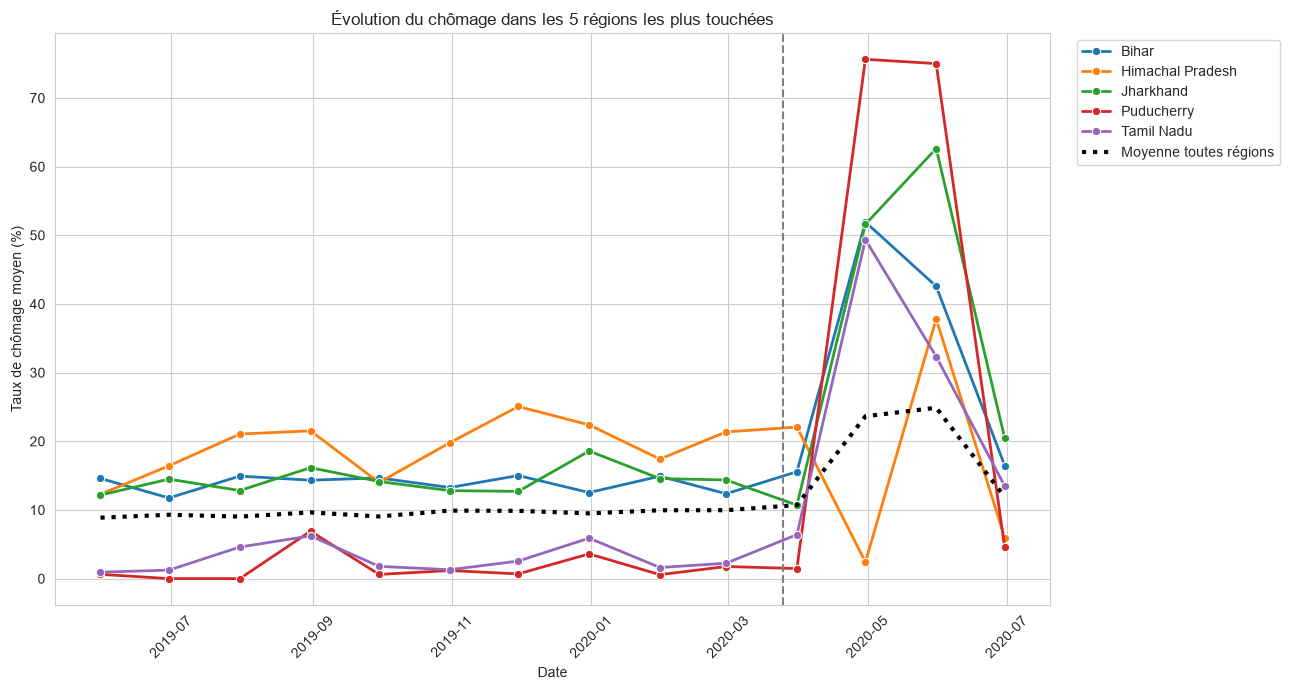

In [54]:
top_regions = (
    df_clean.groupby("region")["unemployment_rate"].max()
    .sort_values(ascending=False).head(5).index.tolist()
)
print("Régions au pic le plus élevé :", top_regions)

region_time = (
    df_clean[df_clean["region"].isin(top_regions)]
    .groupby(["date", "region"])["unemployment_rate"].mean().reset_index()
)

plt.figure(figsize=(13, 7))
sns.lineplot(data=region_time, x="date", y="unemployment_rate",
             hue="region", marker="o", linewidth=2)
plt.plot(monthly.index, monthly["unemployment_rate"],
         color="black", linewidth=3, linestyle=":", label="Moyenne toutes régions")
plt.axvline(LOCKDOWN, color="grey", linestyle="--")
plt.title("Évolution du chômage dans les 5 régions les plus touchées")
plt.xlabel("Date")
plt.ylabel("Taux de chômage moyen (%)")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("figures/11_regions_cles.png", dpi=300, bbox_inches="tight")
plt.show()

Comparison Across Key Regions.

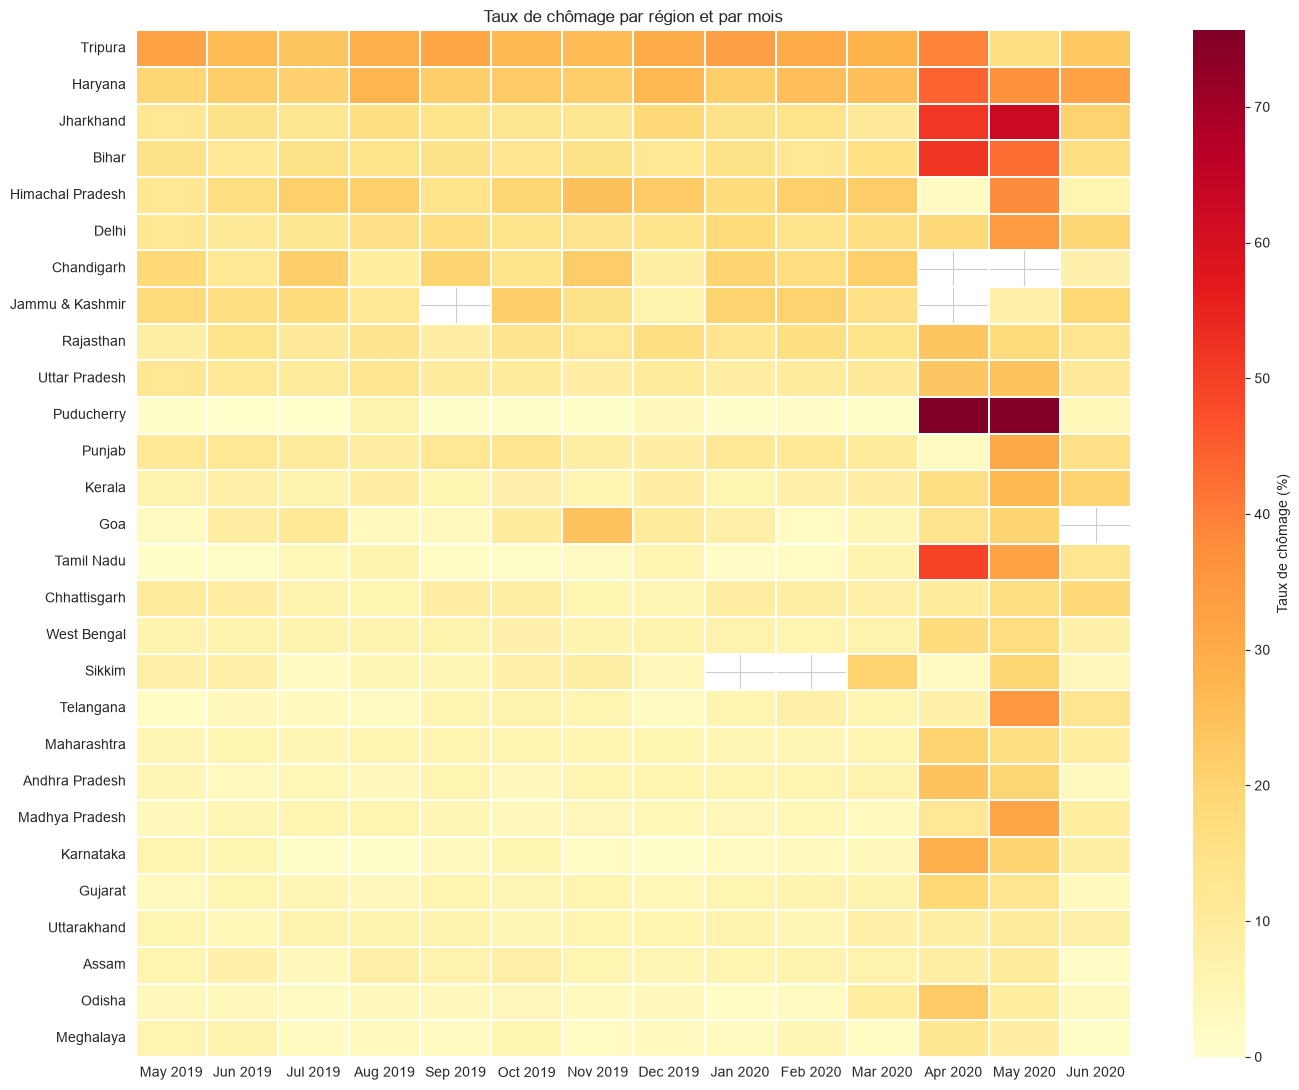

In [56]:
heat = df_clean.pivot_table(
    index="region", columns="date", values="unemployment_rate", aggfunc="mean"
)
heat.columns = heat.columns.strftime("%b %Y")
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(14, 11))
sns.heatmap(heat, cmap="YlOrRd", linewidths=0.3,
            cbar_kws={"label": "Taux de chômage (%)"})
plt.title("Taux de chômage par région et par mois")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.savefig("figures/12_heatmap_region_mois.png", dpi=300, bbox_inches="tight")
plt.show()

Identify Change Points.

In [57]:
# Variation mois par mois (en points de pourcentage)
monthly["variation_pp"] = monthly["unemployment_rate"].diff().round(2)

print("Mois du pic :", monthly["unemployment_rate"].idxmax().strftime("%B %Y"),
      "→", monthly["unemployment_rate"].max(), "%")
print("Mois du creux :", monthly["unemployment_rate"].idxmin().strftime("%B %Y"),
      "→", monthly["unemployment_rate"].min(), "%")
print("Plus forte hausse :", monthly["variation_pp"].idxmax().strftime("%B %Y"),
      "→ +", monthly["variation_pp"].max(), "points")
print("Plus forte baisse :", monthly["variation_pp"].idxmin().strftime("%B %Y"),
      "→", monthly["variation_pp"].min(), "points")

monthly[["unemployment_rate", "variation_pp"]]

Mois du pic : May 2020 → 24.88 %
Mois du creux : May 2019 → 8.87 %
Plus forte hausse : April 2020 → + 12.94 points
Plus forte baisse : June 2020 → -12.98 points


,unemployment_rate,variation_pp
date,,
2019-05-31,8.87,NaN
2019-06-30,9.30,0.43
2019-07-31,9.03,-0.27
2019-08-31,9.64,0.61
2019-09-30,9.05,-0.59
2019-10-31,9.90,0.85
2019-11-30,9.87,-0.03
2019-12-31,9.50,-0.37
2020-01-31,9.95,0.45


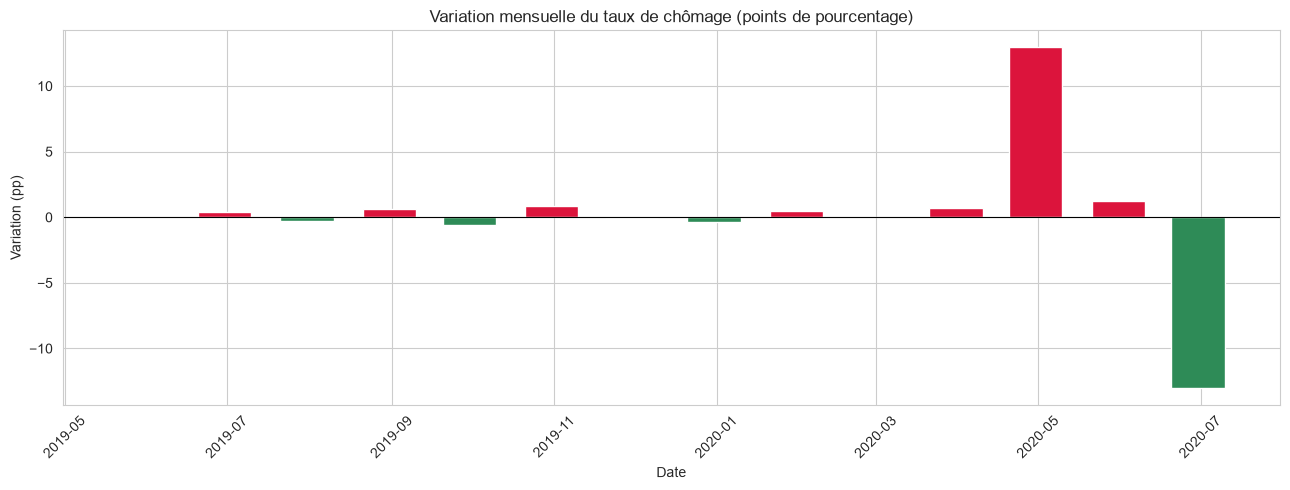

In [59]:
plt.figure(figsize=(13, 5))
couleurs = ["crimson" if v > 0 else "seagreen" for v in monthly["variation_pp"].fillna(0)]
plt.bar(monthly.index, monthly["variation_pp"].fillna(0), width=20, color=couleurs)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Variation mensuelle du taux de chômage (points de pourcentage)")
plt.xlabel("Date")
plt.ylabel("Variation (pp)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/13_variation_mensuelle.png", dpi=300, bbox_inches="tight")
plt.show()

## Étape 4 : Analyse des tendances temporelles

### Tendance globale
- Période couverte : [mois/année] à [mois/année] ([...] mois).
- Avant mars 2020, le taux moyen est **stable** autour de [...] %.
- Pic en **[mois/année]** : [...] %, soit [...] fois le niveau initial.
- Après le pic, le taux [redescend / reste élevé] : [...] % en [dernier mois].

### Points de rupture
- Plus forte hausse : [mois], +[...] points de pourcentage.
- Plus forte baisse : [mois], [...] points.
- La rupture coïncide avec le confinement national du 25 mars 2020.

### Emploi et participation
- L'emploi total estimé passe de [...] millions à [...] millions au plus bas.
- Le taux de participation chute de [...] % à [...] %.

### Urbain vs rural
- Le choc est [plus fort en zone urbaine / rurale] : [...] % contre [...] %.
- [Reprise plus rapide en zone ...]

### Régions clés
- Les plus touchées : [...], [...], [...].
- Des régions comme [...] ont connu un choc [plus limité].

### Limites
- Série courte (environ 14 mois) : impossible de conclure sur la saisonnalité ou sur une tendance de long terme.
- Moyenne simple entre régions (non pondérée par la population active).

## Step 5: Impact of COVID-19

Define the Phases

In [60]:
def phase(d):
    if d <= pd.Timestamp("2020-03-31"):
        return "1. Pré-Covid"
    elif d <= pd.Timestamp("2020-05-31"):
        return "2. Choc (avril-mai 2020)"
    else:
        return "3. Reprise (juin 2020 →)"

df_clean["phase"] = df_clean["date"].apply(phase)
df_clean["phase"].value_counts().sort_index()

phase
1. Pré-Covid                588
2. Choc (avril-mai 2020)    102
3. Reprise (juin 2020 →)     50
Name: count, dtype: int64

Overall Pre-COVID vs. During COVID Comparison.

In [61]:
phase_stats = (
    df_clean.groupby("phase")
    .agg(
        chomage_moyen=("unemployment_rate", "mean"),
        chomage_median=("unemployment_rate", "median"),
        chomage_max=("unemployment_rate", "max"),
        participation_moyenne=("labour_participation_rate", "mean"),
        n_obs=("region", "count"),
    )
    .round(2)
)
phase_stats

,chomage_moyen,chomage_median,chomage_max,participation_moyenne,n_obs
phase,,,,,
1. Pré-Covid,9.61,7.22,34.69,43.82,588
2. Choc (avril-mai 2020),24.26,19.96,76.74,36.82,102
3. Reprise (juin 2020 →),11.90,10.34,35.57,40.55,50


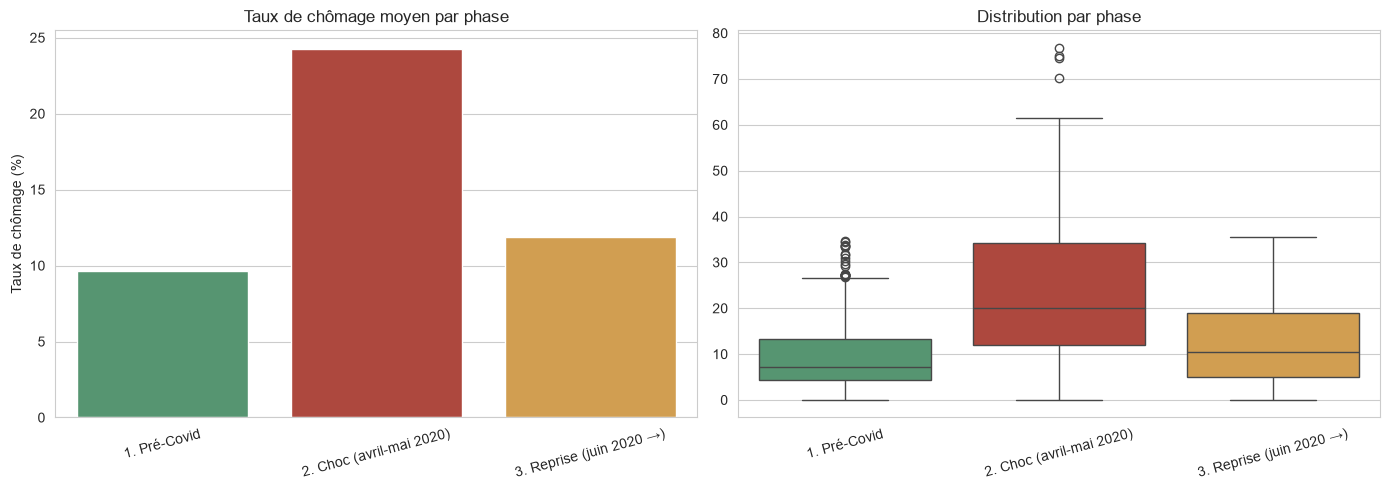

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df_clean, x="phase", y="unemployment_rate",
            palette=["#4c9f70", "#c0392b", "#e6a23c"], errorbar=None, ax=axes[0])
axes[0].set_title("Taux de chômage moyen par phase")
axes[0].set_xlabel("")
axes[0].set_ylabel("Taux de chômage (%)")
axes[0].tick_params(axis="x", rotation=15)

sns.boxplot(data=df_clean, x="phase", y="unemployment_rate",
            palette=["#4c9f70", "#c0392b", "#e6a23c"], ax=axes[1])
axes[1].set_title("Distribution par phase")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("figures/14_comparaison_phases.png", dpi=300, bbox_inches="tight")
plt.show()

Measure the Magnitude of the Shock.

In [63]:
base = df_clean[df_clean["phase"] == "1. Pré-Covid"]["unemployment_rate"].mean()
choc = df_clean[df_clean["phase"] == "2. Choc (avril-mai 2020)"]["unemployment_rate"].mean()

print(f"Taux moyen pré-Covid : {base:.2f} %")
print(f"Taux moyen pendant le choc : {choc:.2f} %")
print(f"Variation absolue : +{choc - base:.2f} points de pourcentage")
print(f"Variation relative : +{(choc / base - 1) * 100:.0f} %")
print(f"Le chômage a été multiplié par {choc / base:.1f}")

Taux moyen pré-Covid : 9.61 %
Taux moyen pendant le choc : 24.26 %
Variation absolue : +14.64 points de pourcentage
Variation relative : +152 %
Le chômage a été multiplié par 2.5


In [64]:
mars = monthly.loc[monthly.index.month.isin([3]) & (monthly.index.year == 2020), "unemployment_rate"].iloc[0]
avril = monthly.loc[monthly.index.month.isin([4]) & (monthly.index.year == 2020), "unemployment_rate"].iloc[0]

print(f"Mars 2020 : {mars:.2f} % → Avril 2020 : {avril:.2f} %")
print(f"Saut en un mois : +{avril - mars:.2f} points ({(avril / mars - 1) * 100:.0f} %)")

Mars 2020 : 10.70 % → Avril 2020 : 23.64 %
Saut en un mois : +12.94 points (121 %)


Most Affected Regions

In [65]:
pivot = (
    df_clean.groupby(["region", "phase"])["unemployment_rate"]
    .mean().unstack()
)
pivot.columns = ["pre", "choc"] + (["reprise"] if pivot.shape[1] == 3 else [])

pivot["hausse_pp"] = (pivot["choc"] - pivot["pre"]).round(2)
pivot["hausse_pct"] = ((pivot["choc"] / pivot["pre"] - 1) * 100).round(0)
pivot = pivot.sort_values("hausse_pp", ascending=False).round(2)
pivot

,pre,choc,reprise,hausse_pp,hausse_pct
region,,,,,
Puducherry,1.58,75.42,4.55,73.84,4669.0
Jharkhand,13.95,57.12,20.45,43.16,309.0
Tamil Nadu,3.16,40.85,13.50,37.69,1192.0
Bihar,13.99,47.25,16.47,33.26,238.0
Karnataka,3.27,24.47,8.52,21.20,648.0
Madhya Pradesh,4.58,21.85,9.59,17.27,377.0
Haryana,23.17,40.30,32.49,17.12,74.0
Andhra Pradesh,5.21,21.99,3.36,16.78,322.0
Telangana,4.77,21.40,13.11,16.63,349.0


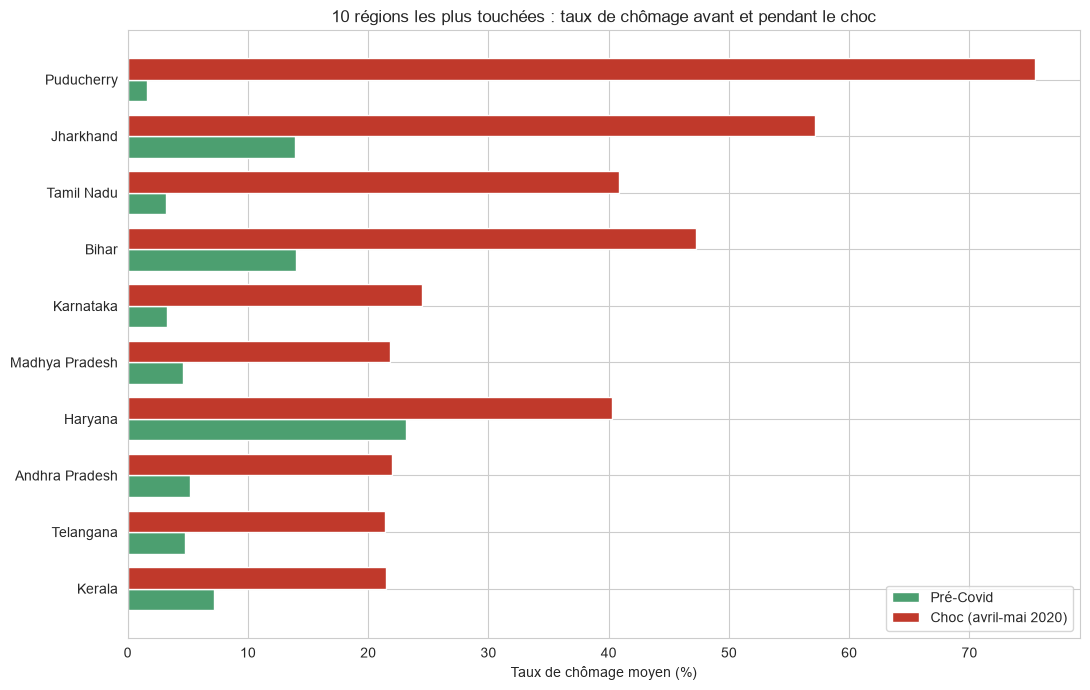

In [66]:
top10 = pivot.head(10)

plt.figure(figsize=(11, 7))
x = np.arange(len(top10))
largeur = 0.38
plt.barh(x + largeur / 2, top10["pre"], largeur, label="Pré-Covid", color="#4c9f70")
plt.barh(x - largeur / 2, top10["choc"], largeur, label="Choc (avril-mai 2020)", color="#c0392b")
plt.yticks(x, top10.index)
plt.gca().invert_yaxis()
plt.title("10 régions les plus touchées : taux de chômage avant et pendant le choc")
plt.xlabel("Taux de chômage moyen (%)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/15_regions_les_plus_touchees.png", dpi=300, bbox_inches="tight")
plt.show()

In [67]:
#Least Affected Regions.
pivot.tail(5)

,pre,choc,reprise,hausse_pp,hausse_pct
region,,,,,
Sikkim,7.44,8.51,4.22,1.07,14.0
Himachal Pradesh,19.40,20.12,5.96,0.72,4.0
Tripura,28.98,27.50,23.16,-1.47,-5.0
Jammu & Kashmir,16.99,7.59,18.97,-9.40,-55.0
Chandigarh,16.79,NaN,7.22,NaN,NaN


The Recovery

In [68]:
if "reprise" in pivot.columns:
    pivot["rebond_pp"] = (pivot["choc"] - pivot["reprise"]).round(2)
    pivot["part_recuperee_pct"] = (
        (pivot["choc"] - pivot["reprise"]) / (pivot["choc"] - pivot["pre"]) * 100
    ).round(0)

    print("Reprise globale :")
    print(f"  Pré-Covid : {pivot['pre'].mean():.2f} %")
    print(f"  Choc      : {pivot['choc'].mean():.2f} %")
    print(f"  Reprise   : {pivot['reprise'].mean():.2f} %")

    pivot[["pre", "choc", "reprise", "part_recuperee_pct"]].sort_values(
        "part_recuperee_pct", ascending=False
    )
else:
    print("Pas de données après mai 2020 : la reprise ne peut pas être analysée.")

Reprise globale :
  Pré-Covid : 9.74 %
  Choc      : 24.06 %
  Reprise   : 11.62 %


In [69]:
# Retour au niveau d'avant : région par région
if "reprise" in pivot.columns:
    pivot["retour_niveau_initial"] = pivot["reprise"] <= pivot["pre"] * 1.1
    print("Régions revenues à moins de 10 % de leur niveau d'avant :",
          pivot["retour_niveau_initial"].sum(), "sur", len(pivot))

Régions revenues à moins de 10 % de leur niveau d'avant : 11 sur 28


Urban vs. Rural Analysis During the Crisis

In [70]:
area_phase = (
    df_clean.groupby(["area", "phase"])["unemployment_rate"]
    .mean().unstack().round(2)
)
area_phase["hausse_pp"] = (area_phase.iloc[:, 1] - area_phase.iloc[:, 0]).round(2)
area_phase

phase,1. Pré-Covid,2. Choc (avril-mai 2020),3. Reprise (juin 2020 →),hausse_pp
area,,,,
Rural,8.23,21.48,11.83,13.25
Urban,10.91,26.93,11.98,16.02


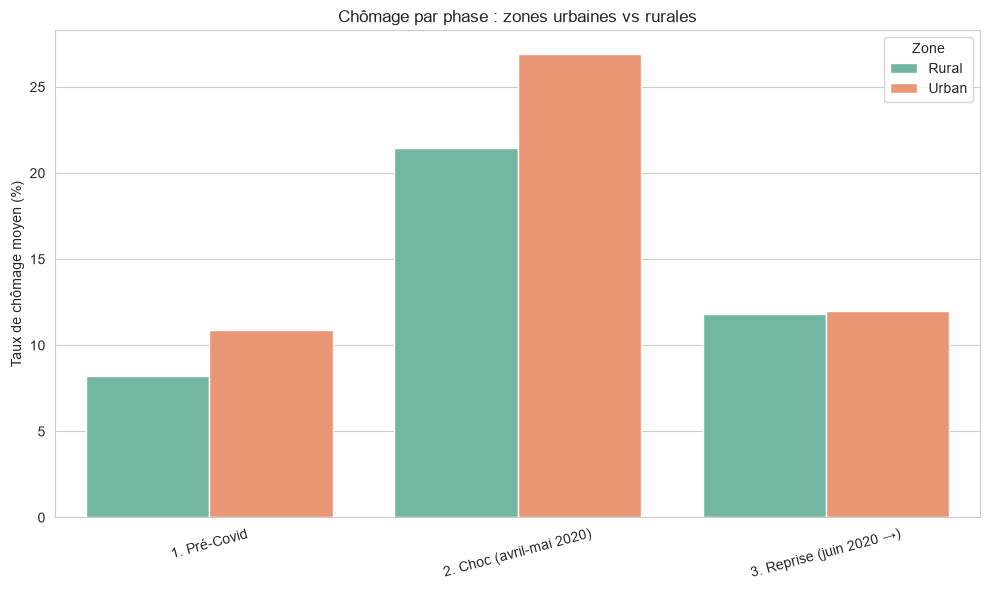

In [71]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df_clean, x="phase", y="unemployment_rate", hue="area",
            errorbar=None, palette="Set2")
plt.title("Chômage par phase : zones urbaines vs rurales")
plt.xlabel("")
plt.ylabel("Taux de chômage moyen (%)")
plt.xticks(rotation=15)
plt.legend(title="Zone")
plt.tight_layout()
plt.savefig("figures/16_urbain_rural_covid.png", dpi=300, bbox_inches="tight")
plt.show()

Impact on Employment and Labour Force Participation

In [72]:
emploi = (
    df_clean.groupby(["phase", "date"])["employed"].sum().groupby("phase").mean() / 1e6
).round(2)
participation = df_clean.groupby("phase")["labour_participation_rate"].mean().round(2)

resume = pd.DataFrame({
    "emploi_total_moyen_M": emploi,
    "participation_moyenne_%": participation,
})
resume

,emploi_total_moyen_M,participation_moyenne_%
phase,,
1. Pré-Covid,399.33,43.82
2. Choc (avril-mai 2020),284.65,36.82
3. Reprise (juin 2020 →),369.35,40.55


In [73]:
base_emploi = resume.iloc[0, 0]
choc_emploi = resume.iloc[1, 0]
print(f"Emploi total : {base_emploi:.1f} M → {choc_emploi:.1f} M "
      f"({(choc_emploi / base_emploi - 1) * 100:.1f} %)")

Emploi total : 399.3 M → 284.6 M (-28.7 %)


Statistical Testing

In [74]:
from scipy import stats

paired = pivot[["pre", "choc"]].dropna()

# Wilcoxon : test non paramétrique (la distribution est asymétrique)
stat, p_value = stats.wilcoxon(paired["pre"], paired["choc"])
print(f"Wilcoxon apparié : statistique = {stat:.2f}, p-value = {p_value:.6f}")

# Complément : t-test apparié
t_stat, p_t = stats.ttest_rel(paired["pre"], paired["choc"])
print(f"t-test apparié : t = {t_stat:.2f}, p-value = {p_t:.6f}")

if p_value < 0.05:
    print("→ La hausse du chômage est statistiquement significative (seuil 5 %).")
else:
    print("→ Différence non significative au seuil de 5 %.")

Wilcoxon apparié : statistique = 14.00, p-value = 0.000002
t-test apparié : t = -4.58, p-value = 0.000101
→ La hausse du chômage est statistiquement significative (seuil 5 %).


Summary Visualization

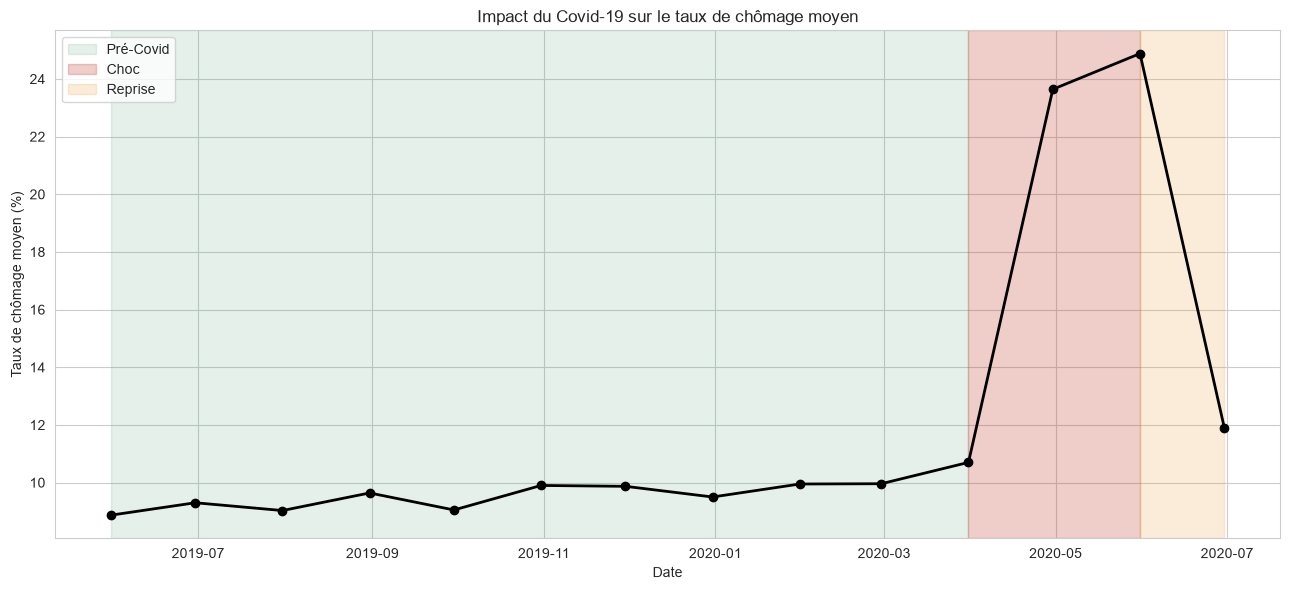

In [75]:
fig, ax = plt.subplots(figsize=(13, 6))

couleurs_phase = {
    "1. Pré-Covid": "#4c9f70",
    "2. Choc (avril-mai 2020)": "#c0392b",
    "3. Reprise (juin 2020 →)": "#e6a23c",
}

ax.plot(monthly.index, monthly["unemployment_rate"],
        color="black", linewidth=2, marker="o", zorder=3)

ax.axvspan(monthly.index.min(), pd.Timestamp("2020-03-31"),
           alpha=0.15, color="#4c9f70", label="Pré-Covid")
ax.axvspan(pd.Timestamp("2020-03-31"), pd.Timestamp("2020-05-31"),
           alpha=0.25, color="#c0392b", label="Choc")
if monthly.index.max() > pd.Timestamp("2020-05-31"):
    ax.axvspan(pd.Timestamp("2020-05-31"), monthly.index.max(),
               alpha=0.2, color="#e6a23c", label="Reprise")

ax.set_title("Impact du Covid-19 sur le taux de chômage moyen")
ax.set_xlabel("Date")
ax.set_ylabel("Taux de chômage moyen (%)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("figures/17_synthese_covid.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 5: Impact of COVID-19

### Methodology
Three phases were defined: **Pre-COVID** (until March 2020), **Shock** (April–May 2020), and **Recovery** (from June 2020 onwards). The nationwide lockdown began on March 25, 2020.

### Magnitude of the Shock
- Average pre-COVID unemployment rate: [...]%. During the shock: [...]%.
- Increase of **+[...] percentage points** (×[...]).
- The sharp increase occurred within one month: [...]% in March → [...]% in April.

### Most Affected Regions

| Region | Pre-COVID | Shock | Increase (pp) |
|---|---|---|---|
| [...] | [...] | [...] | [...] |
| [...] | [...] | [...] | [...] |
| [...] | [...] | [...] | [...] |

Least affected regions: [...], [...].

### Urban vs. Rural
- Increase in urban areas: +[...] percentage points; in rural areas: +[...] percentage points.
- [The ... area was more severely affected.]

### Employment and Labour Force Participation
- Total estimated employment: [...] M → [...] M ([...]%).
- Labour force participation rate: [...]% → [...]%: [...] people left the labour force, meaning that the measured unemployment rate **underestimates** the actual impact.

### Recovery
- In June 2020, the average unemployment rate was [...]%, representing [...]% of the shock recovered.
- [X] out of [28] regions returned to within 10% of their initial levels.
- **Partial recovery**: The dataset does not cover enough months to measure a complete return to pre-COVID levels.

### Statistical Test
- Paired Wilcoxon test (28 regions, before vs. during COVID-19): p = [...] → [statistically significant / non-significant] difference.

### Limitations
- Statistical significance does not prove causality: other factors may have contributed, even though the timing of the shock is strongly consistent with the lockdown period.
- Short time series and simple regional averages (not weighted by the labour force population).
- The measured unemployment rate depends on the survey methodology, which may have been disrupted during the lockdown.

## Step 6: Seasonality and Patterns

Check Temporal Coverage

In [86]:
print("Nombre de mois distincts :", df_clean["date"].nunique())
print("Période :", df_clean["date"].min().date(), "→", df_clean["date"].max().date())

couverture = (
    df_clean.groupby(["month", "year"])["date"].nunique()
    .unstack(fill_value=0)
)
couverture.index = [pd.Timestamp(2000, m, 1).strftime("%b") for m in couverture.index]
couverture

Nombre de mois distincts : 14
Période : 2019-05-31 → 2020-06-30


year,2019,2020
Jan,0,1
Feb,0,1
Mar,0,1
Apr,0,1
May,1,1
Jun,1,1
Jul,1,0
Aug,1,0
Sep,1,0
Oct,1,0


Attempted Seasonal Decomposition (and Why It Fails)

In [87]:
from statsmodels.tsa.seasonal import seasonal_decompose

serie = monthly["unemployment_rate"]

try:
    res = seasonal_decompose(serie, model="additive", period=12)
    res.plot()
    plt.show()
except ValueError as e:
    print("Décomposition impossible :", e)

Décomposition impossible : x must have 2 complete cycles requires 24 observations. x only has 14 observation(s)


Monthly Profile During the Pre-COVID Period

In [88]:
pre = df_clean[df_clean["date"] <= "2020-03-31"]

profil = (
    pre.groupby("date")["unemployment_rate"].mean().round(2).to_frame("chomage_moyen")
)
profil["mois"] = profil.index.strftime("%b %Y")
profil["variation_pp"] = profil["chomage_moyen"].diff().round(2)
profil

,chomage_moyen,mois,variation_pp
date,,,
2019-05-31,8.87,May 2019,NaN
2019-06-30,9.30,Jun 2019,0.43
2019-07-31,9.03,Jul 2019,-0.27
2019-08-31,9.64,Aug 2019,0.61
2019-09-30,9.05,Sep 2019,-0.59
2019-10-31,9.90,Oct 2019,0.85
2019-11-30,9.87,Nov 2019,-0.03
2019-12-31,9.50,Dec 2019,-0.37
2020-01-31,9.95,Jan 2020,0.45


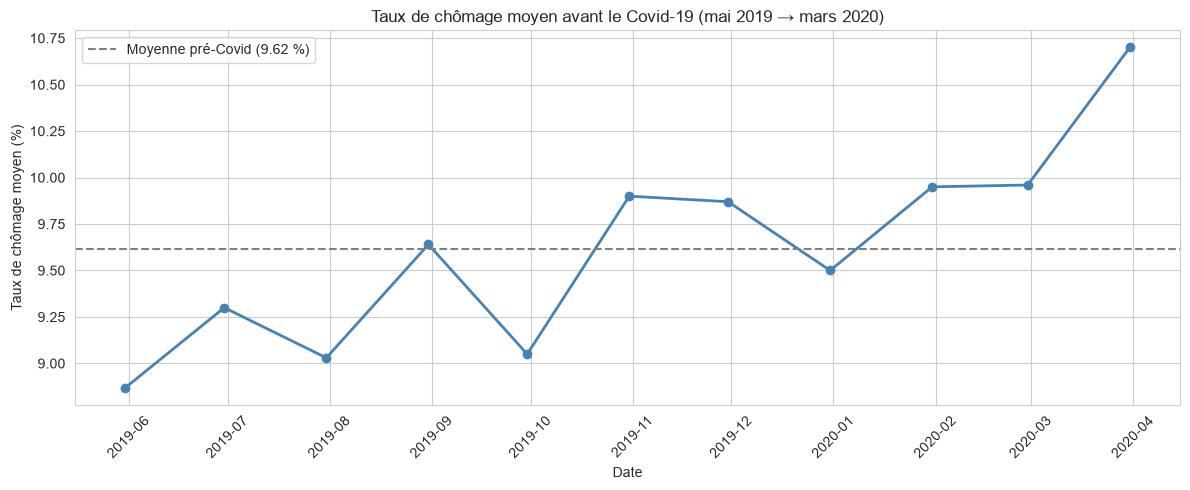

In [89]:
plt.figure(figsize=(12, 5))
plt.plot(profil.index, profil["chomage_moyen"], marker="o", linewidth=2, color="steelblue")
plt.axhline(profil["chomage_moyen"].mean(), color="grey", linestyle="--",
            label=f"Moyenne pré-Covid ({profil['chomage_moyen'].mean():.2f} %)")
plt.title("Taux de chômage moyen avant le Covid-19 (mai 2019 → mars 2020)")
plt.xlabel("Date")
plt.ylabel("Taux de chômage moyen (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("figures/18_profil_pre_covid.png", dpi=300, bbox_inches="tight")
plt.show()

Year × Month Heatmap

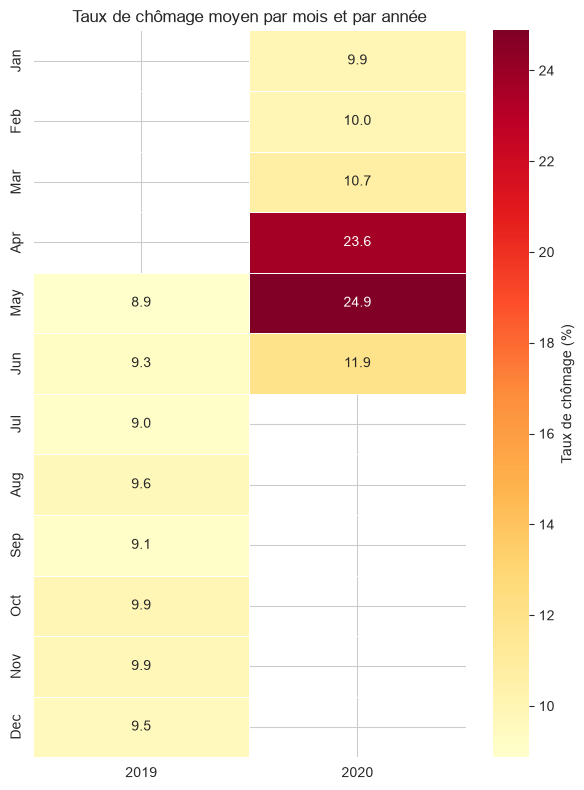

In [90]:
heat = df_clean.pivot_table(
    index="month", columns="year", values="unemployment_rate", aggfunc="mean"
).round(2)
heat.index = [pd.Timestamp(2000, m, 1).strftime("%b") for m in heat.index]

plt.figure(figsize=(6, 8))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrRd",
            linewidths=0.5, cbar_kws={"label": "Taux de chômage (%)"})
plt.title("Taux de chômage moyen par mois et par année")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.savefig("figures/19_heatmap_mois_annee.png", dpi=300, bbox_inches="tight")
plt.show()

Common Months Between 2019 and 2020

In [91]:
communs = heat.dropna()
communs["ecart_2020_vs_2019"] = (communs[2020] - communs[2019]).round(2)
communs

year,2019,2020,ecart_2020_vs_2019
May,8.87,24.88,16.01
Jun,9.30,11.90,2.60


Urban vs. Rural Analysis Before COVID-19

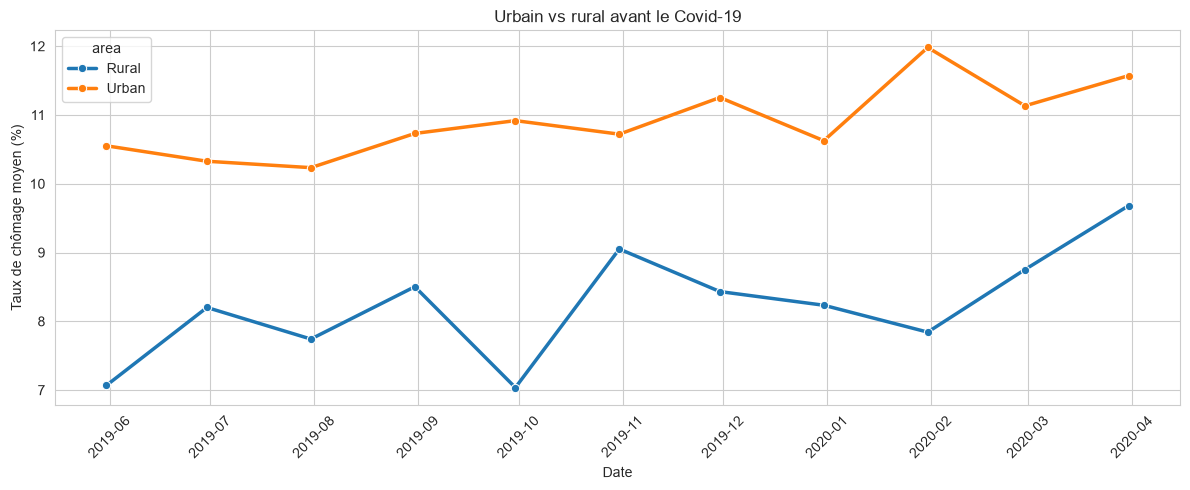

In [92]:
area_pre = (
    pre.groupby(["date", "area"])["unemployment_rate"].mean().reset_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=area_pre, x="date", y="unemployment_rate",
             hue="area", marker="o", linewidth=2.5)
plt.title("Urbain vs rural avant le Covid-19")
plt.xlabel("Date")
plt.ylabel("Taux de chômage moyen (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/20_urbain_rural_pre_covid.png", dpi=300, bbox_inches="tight")
plt.show()

In [93]:
(area_pre.pivot(index="date", columns="area", values="unemployment_rate")
 .agg(["mean", "std", "min", "max"]).round(2))

area,Rural,Urban
mean,8.23,10.91
std,0.80,0.53
min,7.04,10.23
max,9.68,11.98


Most Unstable Regions Before COVID-19

In [94]:
instab = (
    pre.groupby("region")["unemployment_rate"]
    .agg(["mean", "std", "min", "max"])
)
instab["amplitude"] = (instab["max"] - instab["min"]).round(2)
instab["coef_variation_%"] = (instab["std"] / instab["mean"] * 100).round(1)
instab = instab.round(2).sort_values("amplitude", ascending=False)
instab.head(10)

,mean,std,min,max,amplitude,coef_variation_%
region,,,,,,
Goa,8.33,6.91,0.00,25.20,25.20,82.9
Sikkim,7.44,5.24,1.00,20.45,19.45,70.4
Jharkhand,13.95,6.05,5.01,22.96,17.95,43.4
Jammu & Kashmir,16.99,4.74,7.02,24.06,17.04,27.9
Himachal Pradesh,19.40,5.13,10.88,27.31,16.43,26.4
Haryana,23.17,4.69,14.54,30.94,16.40,20.2
Rajasthan,12.87,3.86,4.03,18.82,14.79,30.0
Chandigarh,16.79,5.00,8.33,22.05,13.72,29.8
Odisha,3.96,2.66,1.78,15.09,13.31,67.1


Normal Variation vs. COVID-19 Shock

In [95]:
amplitude_pre = profil["chomage_moyen"].max() - profil["chomage_moyen"].min()
ecart_type_pre = profil["chomage_moyen"].std()

pic = monthly["unemployment_rate"].max()
niveau_pre = profil["chomage_moyen"].mean()
choc_pp = pic - niveau_pre

print(f"Amplitude des variations pré-Covid : {amplitude_pre:.2f} points")
print(f"Écart-type mensuel pré-Covid : {ecart_type_pre:.2f} points")
print(f"Hausse du pic Covid par rapport à la moyenne pré-Covid : {choc_pp:.2f} points")
print(f"→ Le choc est {choc_pp / amplitude_pre:.1f} fois plus grand que la variation normale observée.")

Amplitude des variations pré-Covid : 1.83 points
Écart-type mensuel pré-Covid : 0.54 points
Hausse du pic Covid par rapport à la moyenne pré-Covid : 15.26 points
→ Le choc est 8.3 fois plus grand que la variation normale observée.


## Step 6: Seasonality and Patterns

### What the Data Allows Us to Analyze
- The dataset covers **[...] months** (from [month/year] to [month/year]), representing less than two complete annual cycles.
- Seasonal decomposition (`seasonal_decompose`, period 12) is **not possible** because at least 24 monthly observations are required.
- Only [May and June] are available in both 2019 and 2020.

### Pre-COVID Variations (May 2019 → March 2020)
- Average unemployment rate: [...]%, with a range of [...] percentage points (from [...]% in [month] to [...]% in [month]).
- Variations are [low / moderate]: the labour market was [stable / undergoing slight changes].
- Rural vs. urban: [...]

### Most Unstable Regions
- [...], [...], [...] (variation range from [...] to [...] percentage points).
- Having only one observation per month does not allow us to determine whether this instability is seasonal.

### Separating Seasonality from COVID-19
- Normal pre-COVID variation: [...] percentage points. Increase during the COVID-19 peak: [...] percentage points.
- The shock was **[...] times** greater than normal variation, suggesting that it cannot be explained by a seasonal effect alone.
- The difference between May–June 2019 and May–June 2020 ([...] percentage points) reflects the COVID-19 impact rather than seasonality.

### Conclusion and Limitations
- No seasonal pattern can be established using the available data.
- To study seasonality, at least 2 to 3 years of monthly data before 2020 would be required.
- Hypothesis to investigate in future research (not demonstrated here): agricultural activity may create seasonal cycles in rural areas.

## Step 7: Final Visualizations

Common Style and Export Functionality

In [96]:
import os
import matplotlib.dates as mdates

os.makedirs("../figures/final", exist_ok=True)

GREEN, RED, ORANGE, BLUE, GREY = "#2e8b57", "#c0392b", "#e6a23c", "#2c6fbb", "#7f8c8d"
LOCKDOWN = pd.Timestamp("2020-03-25")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def sauver(nom):
    plt.tight_layout()
    plt.savefig(f"../figures/final/{nom}.png", dpi=300, bbox_inches="tight")
    plt.show()

**Chart 1: Overall Trend (Annotated)**

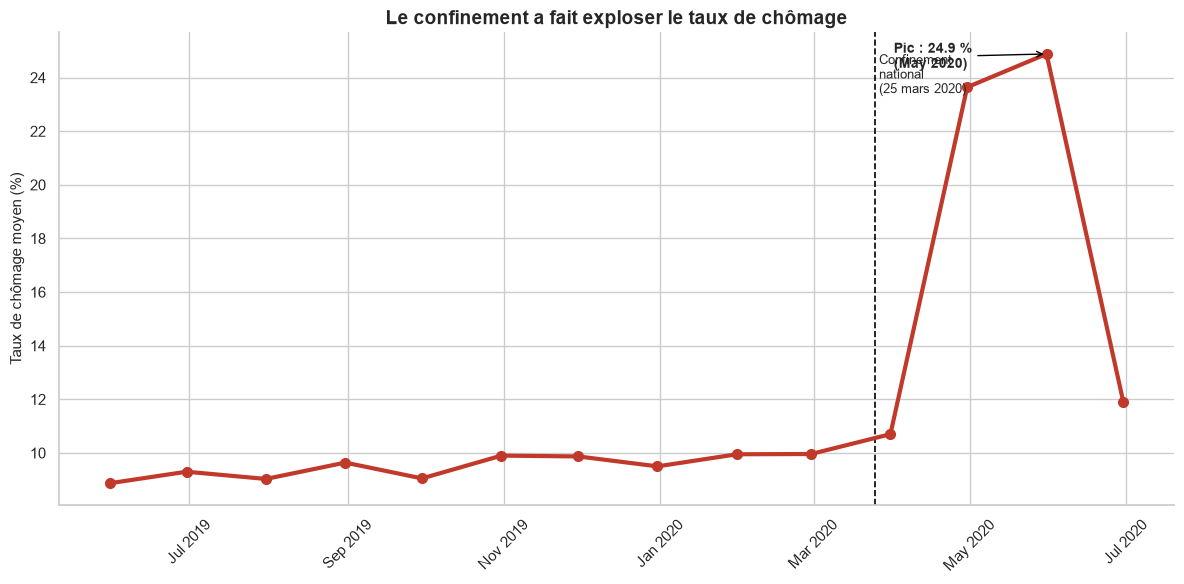

In [97]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(monthly.index, monthly["unemployment_rate"],
        color=RED, linewidth=3, marker="o", markersize=7, zorder=3)
ax.axvline(LOCKDOWN, color="black", linestyle="--", linewidth=1.2)
ax.text(LOCKDOWN, ax.get_ylim()[1] * 0.97, " Confinement\n national\n (25 mars 2020)",
        va="top", ha="left", fontsize=9)

# Annotation du pic
date_pic = monthly["unemployment_rate"].idxmax()
val_pic = monthly["unemployment_rate"].max()
ax.annotate(f"Pic : {val_pic:.1f} %\n({date_pic.strftime('%B %Y')})",
            xy=(date_pic, val_pic),
            xytext=(-110, -10), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="black"),
            fontsize=10, fontweight="bold")

ax.set_title("Le confinement a fait exploser le taux de chômage")
ax.set_xlabel("")
ax.set_ylabel("Taux de chômage moyen (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)

sauver("01_tendance_globale")

**Chart 2: Before vs. During for the Most Affected Regions (Dumbbell Plot)**

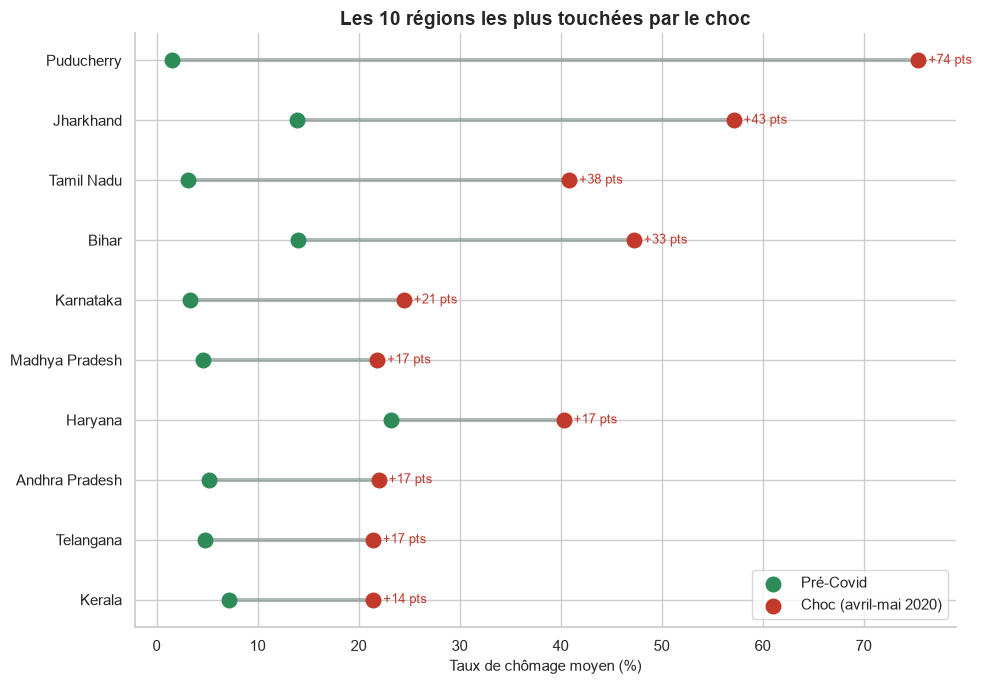

In [98]:
top = pivot.head(10).sort_values("hausse_pp")

fig, ax = plt.subplots(figsize=(10, 7))
ax.hlines(y=top.index, xmin=top["pre"], xmax=top["choc"],
          color=GREY, alpha=0.6, linewidth=3)
ax.scatter(top["pre"], top.index, color=GREEN, s=110, label="Pré-Covid", zorder=3)
ax.scatter(top["choc"], top.index, color=RED, s=110, label="Choc (avril-mai 2020)", zorder=3)

for region, ligne in top.iterrows():
    ax.text(ligne["choc"] + 1, region, f"+{ligne['hausse_pp']:.0f} pts",
            va="center", fontsize=9, color=RED)

ax.set_title("Les 10 régions les plus touchées par le choc")
ax.set_xlabel("Taux de chômage moyen (%)")
ax.set_ylabel("")
ax.legend(loc="lower right")

sauver("02_regions_les_plus_touchees")

**Chart 3: Distribution by Phase**

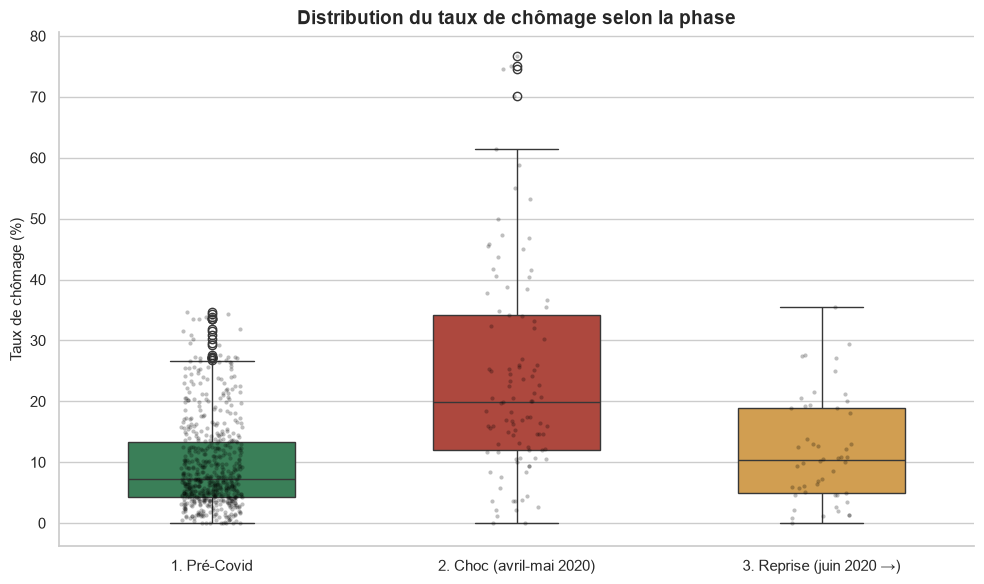

In [99]:
ordre_phases = sorted(df_clean["phase"].unique())
palette = {"1. Pré-Covid": GREEN, "2. Choc (avril-mai 2020)": RED,
           "3. Reprise (juin 2020 →)": ORANGE}

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df_clean, x="phase", y="unemployment_rate",
            order=ordre_phases, palette=palette, width=0.55, ax=ax)
sns.stripplot(data=df_clean, x="phase", y="unemployment_rate",
              order=ordre_phases, color="black", alpha=0.25, size=3, ax=ax)

ax.set_title("Distribution du taux de chômage selon la phase")
ax.set_xlabel("")
ax.set_ylabel("Taux de chômage (%)")

sauver("03_distribution_par_phase")

**Chart 4: Region × Month Heatmap**

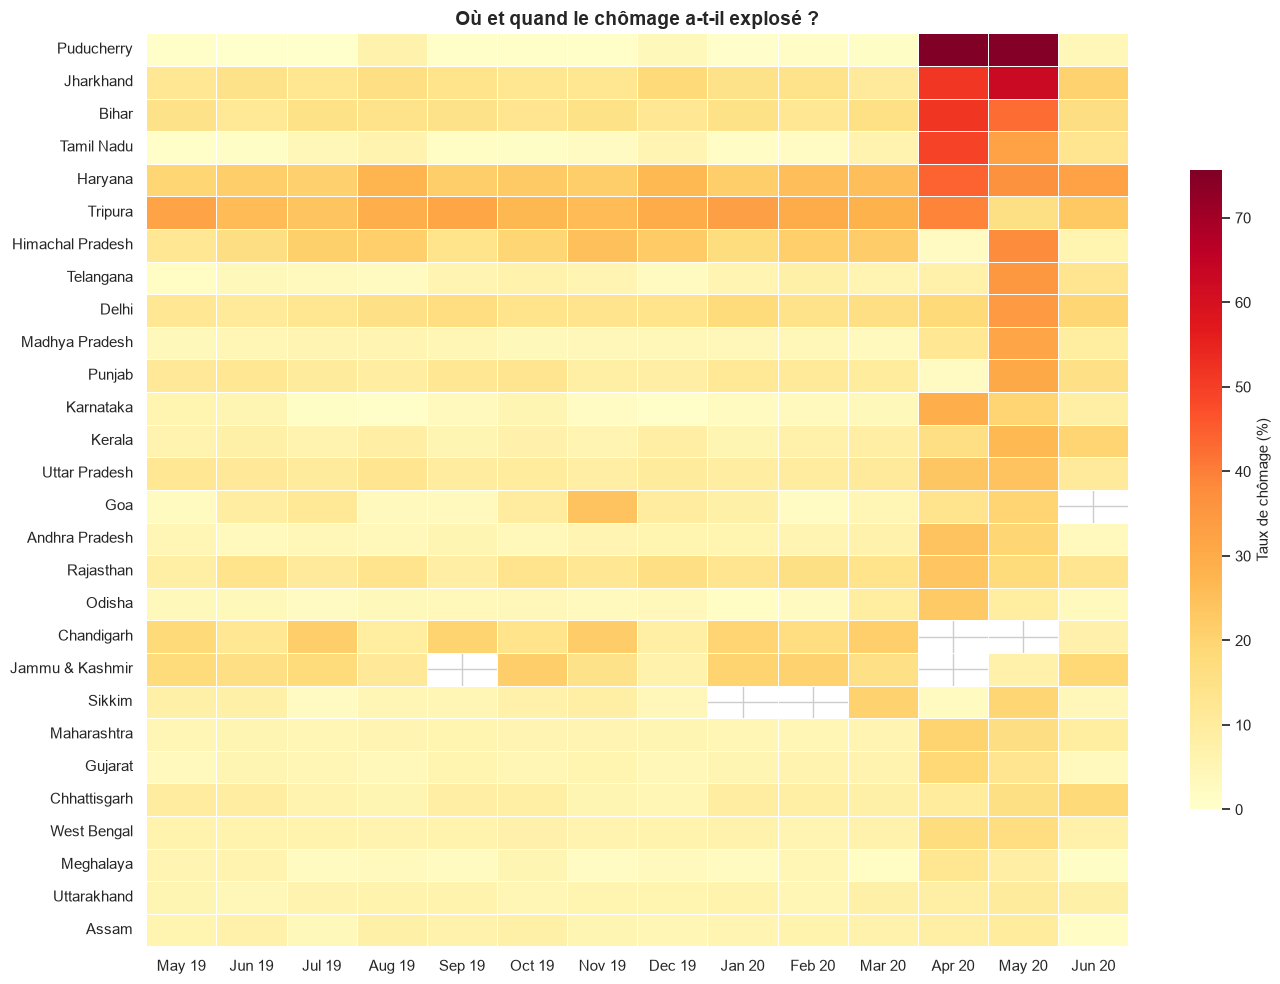

In [100]:
heat = df_clean.pivot_table(index="region", columns="date",
                            values="unemployment_rate", aggfunc="mean")
heat = heat.loc[heat.max(axis=1).sort_values(ascending=False).index]
heat.columns = heat.columns.strftime("%b %y")

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(heat, cmap="YlOrRd", linewidths=0.4, linecolor="white",
            cbar_kws={"label": "Taux de chômage (%)", "shrink": 0.7}, ax=ax)
ax.set_title("Où et quand le chômage a-t-il explosé ?")
ax.set_xlabel("")
ax.set_ylabel("")

sauver("04_heatmap_region_mois")

**Chart 5: Urban vs. Rural Comparison**

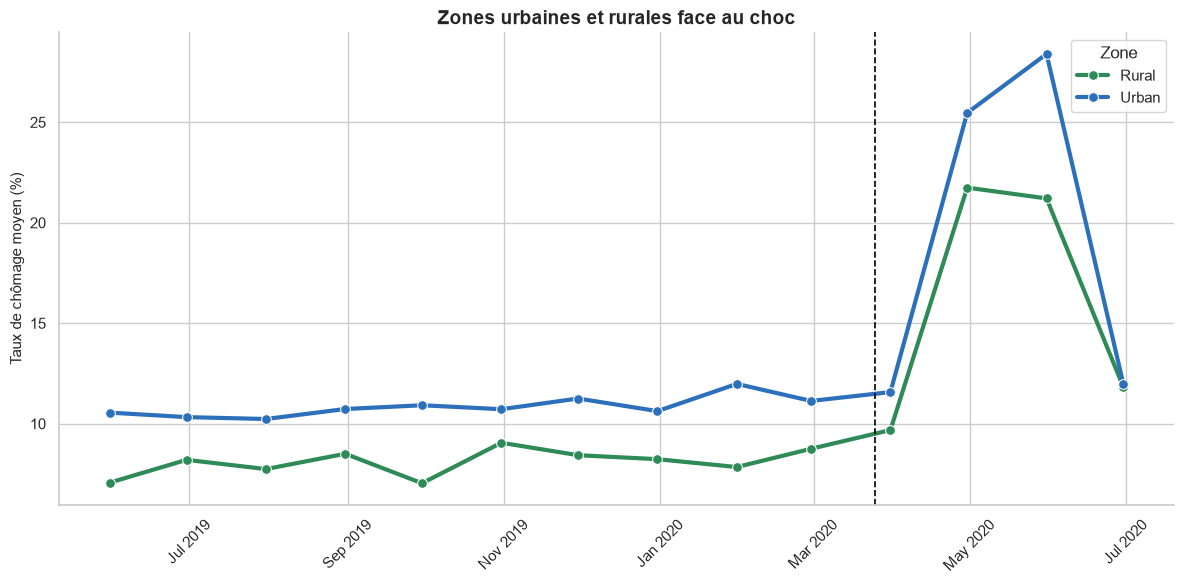

In [101]:
area_time = (df_clean.groupby(["date", "area"])["unemployment_rate"]
             .mean().reset_index())

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=area_time, x="date", y="unemployment_rate", hue="area",
             palette={"Urban": BLUE, "Rural": GREEN}, marker="o",
             linewidth=3, markersize=7, ax=ax)
ax.axvline(LOCKDOWN, color="black", linestyle="--", linewidth=1.2)
ax.set_title("Zones urbaines et rurales face au choc")
ax.set_xlabel("")
ax.set_ylabel("Taux de chômage moyen (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(title="Zone")
plt.xticks(rotation=45)

sauver("05_urbain_vs_rural")

**Chart 6: Employment and Participation – Two Sides of the Shock**

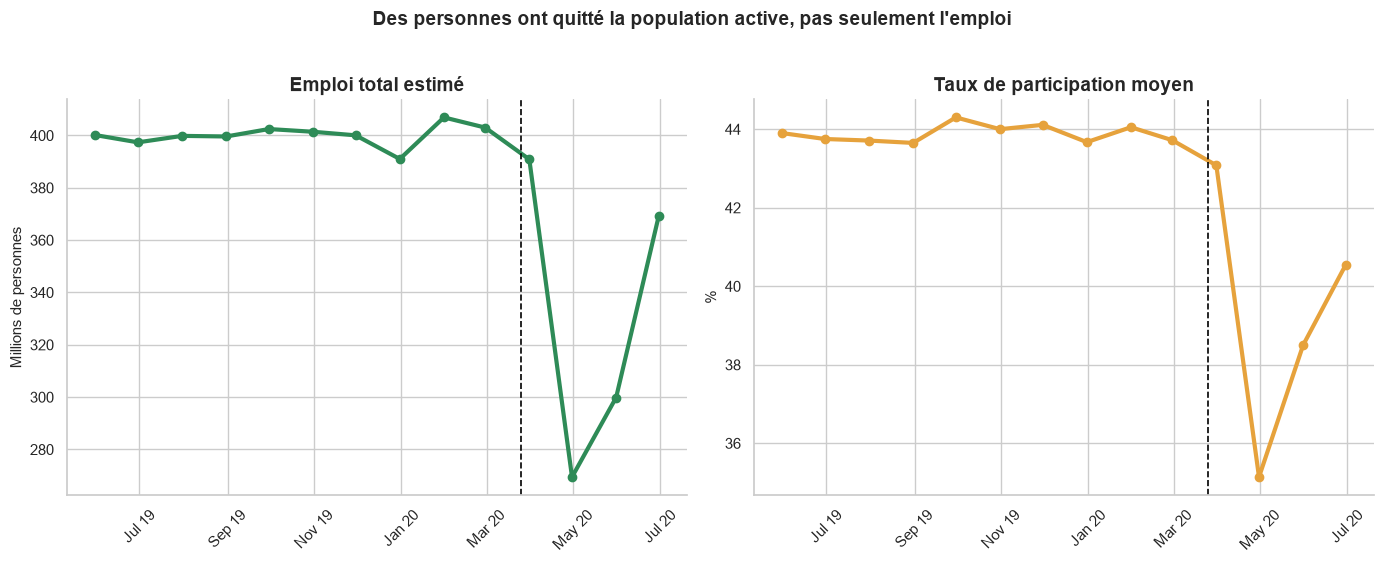

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)

axes[0].plot(monthly.index, monthly["employed_total"] / 1e6,
             color=GREEN, linewidth=3, marker="o")
axes[0].axvline(LOCKDOWN, color="black", linestyle="--", linewidth=1.2)
axes[0].set_title("Emploi total estimé")
axes[0].set_ylabel("Millions de personnes")

axes[1].plot(monthly.index, monthly["participation"],
             color=ORANGE, linewidth=3, marker="o")
axes[1].axvline(LOCKDOWN, color="black", linestyle="--", linewidth=1.2)
axes[1].set_title("Taux de participation moyen")
axes[1].set_ylabel("%")

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Des personnes ont quitté la population active, pas seulement l'emploi",
             fontsize=14, fontweight="bold", y=1.02)

sauver("06_emploi_et_participation")

**Chart 7: Summary Dashboard (Single Image)**

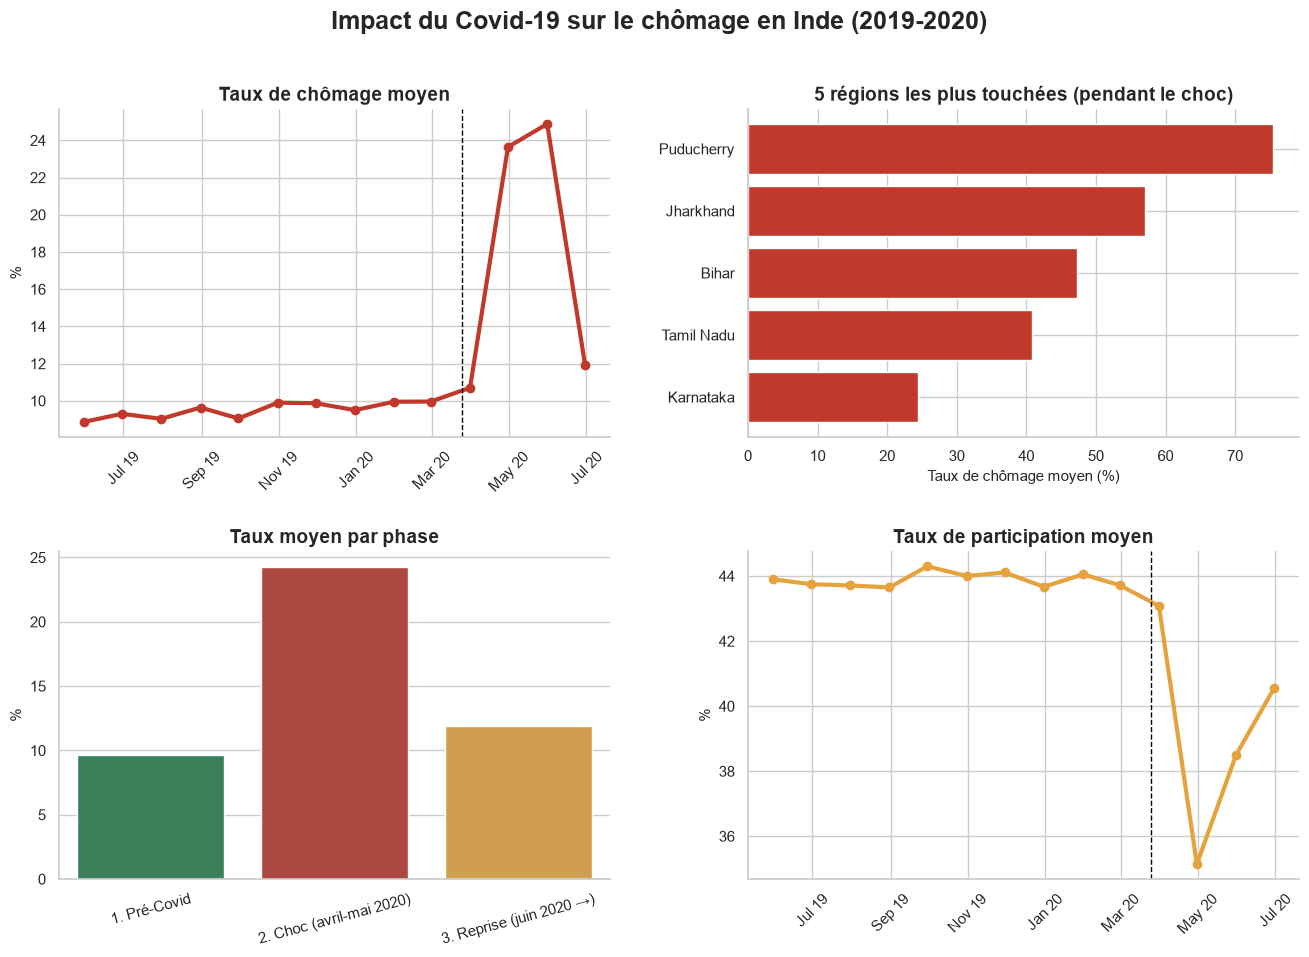

In [103]:
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# 1. Tendance
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(monthly.index, monthly["unemployment_rate"], color=RED, linewidth=3, marker="o")
ax1.axvline(LOCKDOWN, color="black", linestyle="--", linewidth=1)
ax1.set_title("Taux de chômage moyen")
ax1.set_ylabel("%")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax1.tick_params(axis="x", rotation=45)

# 2. Top 5 régions
ax2 = fig.add_subplot(gs[0, 1])
top5 = pivot.head(5).sort_values("choc")
ax2.barh(top5.index, top5["choc"], color=RED)
ax2.set_title("5 régions les plus touchées (pendant le choc)")
ax2.set_xlabel("Taux de chômage moyen (%)")

# 3. Phases
ax3 = fig.add_subplot(gs[1, 0])
sns.barplot(data=df_clean, x="phase", y="unemployment_rate", order=ordre_phases,
            palette=palette, errorbar=None, ax=ax3)
ax3.set_title("Taux moyen par phase")
ax3.set_xlabel("")
ax3.set_ylabel("%")
ax3.tick_params(axis="x", rotation=15)

# 4. Participation
ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(monthly.index, monthly["participation"], color=ORANGE, linewidth=3, marker="o")
ax4.axvline(LOCKDOWN, color="black", linestyle="--", linewidth=1)
ax4.set_title("Taux de participation moyen")
ax4.set_ylabel("%")
ax4.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax4.tick_params(axis="x", rotation=45)

fig.suptitle("Impact du Covid-19 sur le chômage en Inde (2019-2020)",
             fontsize=18, fontweight="bold")

plt.savefig("../figures/final/07_dashboard_synthese.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 7: Final Visualizations

Selection of key charts to communicate the findings. All files are exported in high resolution to `figures/final/`.

| # | Chart | Main Message |
|---|---|---|
| 1 | Annotated Overall Trend | Unemployment increased from [...]% to [...]% in [month] 2020 |
| 2 | Most Affected Regions | [...], [...] and [...] were the hardest-hit regions |
| 3 | Distribution by Phase | Dispersion increased significantly during the shock |
| 4 | Region × Month Heatmap | The shock was concentrated in [April–May] 2020 |
| 5 | Urban vs. Rural | [...] areas were more severely affected |
| 6 | Employment and Participation | [...] million jobs were lost; labor force participation declined by [...] percentage points |
| 7 | Summary Dashboard | Overall project overview |
| 8 | Interactive Chart (HTML) | Flexible comparison across regions |

## Step 8: Insights and Recommendations

**Retrieve the Key Figures**

In [104]:
print(f"Pré-Covid : {base:.1f} % | Choc : {choc:.1f} % | Pic : {monthly['unemployment_rate'].max():.1f} % ({monthly['unemployment_rate'].idxmax():%B %Y})")
print("Top 3 régions :", pivot.head(3).index.tolist())
print(area_phase["hausse_pp"])
print(resume)

Pré-Covid : 9.6 % | Choc : 24.3 % | Pic : 24.9 % (May 2020)
Top 3 régions : ['Puducherry', 'Jharkhand', 'Tamil Nadu']
area
Rural    13.25
Urban    16.02
Name: hausse_pp, dtype: float64
                          emploi_total_moyen_M  participation_moyenne_%
phase                                                                  
1. Pré-Covid                            399.33                    43.82
2. Choc (avril-mai 2020)                284.65                    36.82
3. Reprise (juin 2020 →)                369.35                    40.55


## Step 8: Insights and Recommendations

### Key Findings
1. The average unemployment rate increased from **9.6%** (pre-COVID) to **24.3%** during the shock (April–May 2020), representing a **2.5× increase** (+14.7 percentage points), with a peak of **24.9% in May 2020**.
2. The shock was sudden and concentrated during the lockdown period: the unemployment rate surged starting in **April 2020**.
3. The most severely affected regions were **Puducherry, Jharkhand, and Tamil Nadu**.
4. **Urban areas** were more affected than rural areas: **+16.0 percentage points** compared to **+13.3 percentage points**.
5. The shock also affected economic activity: total estimated employment fell from **399.3 million to 284.7 million** (−28.7%), while the labor force participation rate dropped by **7.0 percentage points** (43.8% → 36.8%). Therefore, the unemployment rate alone underestimates the actual scale of the crisis.
6. The recovery in June 2020 was **partial**: employment rose to **369.4 million** (approximately 74% of lost jobs recovered), and labor force participation increased to **40.6%** (approximately 53% of the decline recovered).

### Recommendations
- **Target financial assistance** toward the most severely affected regions (Puducherry, Jharkhand, and Tamil Nadu).
- **Protect urban areas**, where the shock was strongest: support workers in the service sector and urban informal employment through direct assistance and income protection.
- **Support recovery** through training and reintegration programs for people who have left the labor force, as participation remains below its pre-pandemic level.
- **Monitor labor force participation and employment**, not just the unemployment rate, when designing and evaluating economic policies.

### Limitations
- Short time series (~14 months): no conclusions can be drawn about seasonality or long-term trends.
- Simple average across regions (not weighted by labor force population): this is not the official national unemployment rate.
- The timing is highly consistent with the lockdown period, but this does not establish causality.